In [1]:
# Cells tagged "notes" are for us: they check the numbers quoted in the prose and are dropped
# from the export. Cells tagged "figure" are kept, without their code. See build.py.
%matplotlib inline
import article_figs as F
SME, MGN, DAY = "sm-e-mobo-c", "mg-n-mobo-c", "20260912"

# Calibrating HPWREN Cameras Using the Position of the Stars

*Roy Harnish, October 2026*

HPWREN's mountaintop cameras look out across San Diego County and beyond, a frame a minute, day and night. They serve research, education, and public safety: they catch the smoke of a wildfire, follow weather and flooding as it happens, and show anyone online what the backcountry looks like right now. Being exposed to wind, snow, and other environmental hazards, cameras may shift orientation in time and are no longer aligned exactly to the cardinal directions as they were installed. Calibration is what turns the camera footage into precise measurements. Every pixel in a frame looks out along one direction, and a calibrated camera can indicate the bearing (compass direction) and elevation angle (height above the horizon) of anything in the picture. That precision is needed to say where a smoke column is or to stitch neighboring cameras into one panorama.

A camera's calibration comes in two parts. The intrinsics belong to the camera itself: how its lens bends the scene in front of it onto the sensor, and where the lens is centered on the sensor. They turn a pixel into a direction relative to the camera. The extrinsics place the camera in the world: where it stands and which way it points. Its position is a latitude, longitude, and height above sea level. Its orientation is an azimuth, the compass direction it faces; a tilt, how far the view is aimed above or below the horizon; and a roll, how far the picture is turned about its center.

Together, the two parts turn any pixel into a ray in Earth coordinates. The ray starts at the lens and runs out across the landscape along a known bearing and elevation angle. Such a ray can be laid over a terrain model, a map, or another camera's view. Where it meets the ground is a place on the map, and where two cameras' rays cross is a point in space.

**Where each part comes from.** The position comes from HPWREN's camera table, which lists each site's coordinates and elevation and the camera's height on the tower. Using the stars captured by the camera, we can calculate very precisely which way the camera faces. From the table's position and the frame's time, a star catalog gives every star's direction in that camera's sky to a tiny fraction of a degree.

- **The celestial pole** fixes two of the camera's three angles. Every star circles the pole, and where that center sits relative to the frame pins down how the camera is tipped relative to Earth's axis.
- **The third angle**, a turn about the pole itself, comes from which stars are in the frame and where they sit.
- **The lens** comes from how the spacing between stars changes from the middle of the frame out to its edges.

A camera that films the stars turning overhead for an hour or so is, in effect, photographing a calibration target, and the night sky turns out to be a free and very accurate one. Comparing where the stars appear in the frame with where the catalog says they must be measures the camera's orientation and its lens, without anyone climbing a tower.

This isn't the first time the stars have been used to calibrate HPWREN cameras. Robert Quimby, Director of SDSU's Mount Laguna Observatory, used them to map an HPWREN camera's view onto the sky and line neighboring cameras up into a panorama ([*Using the Stars for Altitude-Azimuth Calibration of HPWREN Cameras*](https://www.hpwren.ucsd.edu/news/20240920/index.html), September 2024). The work described here builds on that idea, automatically across the network.

The software is open source: [star-calibration on GitHub](https://github.com/rharnish/star-calibration). This article is itself generated from a notebook in the same repository, [article.ipynb](https://github.com/rharnish/star-calibration/blob/main/examples/hpwren_article/article.ipynb), which reproduces its figures and numbers. The HPWREN team has built a similar tool based on the ideas presented here and it has been deployed in the production system for PANO mode in October 2026. Unless stated otherwise, every calibration and number in this article comes from star-calibration release [0.4.0](https://github.com/rharnish/star-calibration/tree/v0.4.0), not from HPWREN's tool; the two are compared under Validation.

## How it Works

The solver needs no starting guess for which way the camera faces: it finds the orientation from the stars alone.

1. **Collect a night.** The cameras save a frame every minute. The solver uses ninety images per camera, from midnight to 01:30.
2. **Find what moves with the sky.** In each frame, the tool detects small bright points and links the points from frame to frame into trails. In this release it searches the top 35% of the picture, which assumes the camera is upright, with the sky at the top, as on almost every HPWREN camera. Stars all wheel together around the celestial pole at exactly the rate the Earth turns. Town lights and beacons stay put; aircraft and the texture of lit clouds wander off on their own paths. The tool filters out these types of lights, and the star trails remain.
3. **Find the pole.** Every trail is an arc of a circle around the same point in the sky. Where that point falls in the frame fixes two of the camera's three angles, and how fast the trails turn gives the lens's scale, before a single star has been named.
4. **Match the trails to a star catalog.** Turning the camera's view about the pole, the solver looks for the turn at which catalog stars land on the trails. It then refines azimuth, tilt, roll and the lens together until the match is as tight as it will go. The very brightest stars help find the match, but their images are too big and blurred to pin down precisely, so a second search, over all the sky above the terrain's skyline, adds fainter stars for the final fit.

In [2]:
for name in (SME, MGN):
    s = F.solve(name, DAY)
    r, f, p = s["r"], s["first"], s["r"]["pose"]
    est, _, err = F.pole_fit(s)
    print(f"{name}: pass 1 {len(s['night1'].tracks)} trails, {f['n_stars']} stars {f['median_px']:.2f} px; "
          f"pass 2 {len(s['night'].tracks)} trails, {r['n_stars']} stars {r['median_px']:.2f} px")
    print(f"  heading {(s['cam']['az'] + p['d_az']) % 360:.2f}, tilt {p['d_pitch']:+.2f}, roll {p['d_roll']:+.2f}, "
          f"lens {p['k_ratio']:.4f}x k1 {p['k1']:+.4f}, centre ({s['cam_c']['cx']}, {s['cam_c']['cy']}); "
          f"pole fit {err:.2f} deg from the solved pole")

frames: 90/90 frames dark enough (sun el <= -8.0)


  621 raw tracks -> 45 moving, persistent tracks


frames: 90/90 frames dark enough (sun el <= -8.0)


  1272 raw tracks -> 52 moving, persistent tracks


sm-e-mobo-c: pass 1 46 trails, 35 stars 0.49 px; pass 2 51 trails, 36 stars 0.52 px
  heading 86.43, tilt +1.77, roll -0.84, lens 0.8840x k1 -0.0732, centre (-21.8, -25.2); pole fit 0.26 deg from the solved pole


frames: 90/90 frames dark enough (sun el <= -8.0)
  321 raw tracks -> 29 moving, persistent tracks


frames: 90/90 frames dark enough (sun el <= -8.0)
  407 raw tracks -> 29 moving, persistent tracks


mg-n-mobo-c: pass 1 30 trails, 21 stars 0.99 px; pass 2 29 trails, 22 stars 1.12 px
  heading 359.47, tilt -0.30, roll -0.75, lens 0.8859x k1 -0.0812, centre (5.2, 6.5); pole fit 0.32 deg from the solved pole


### Step 3 in Pictures: Finding the Pole

On a north-facing camera, stacking a night's frames turns every star into an arc, and all the arcs share one center: the celestial pole, close to the North Star. The solver finds that center from the trails' shapes and speeds alone, without naming a single star, and it lands within 0.3° of where the finished calibration puts the pole.

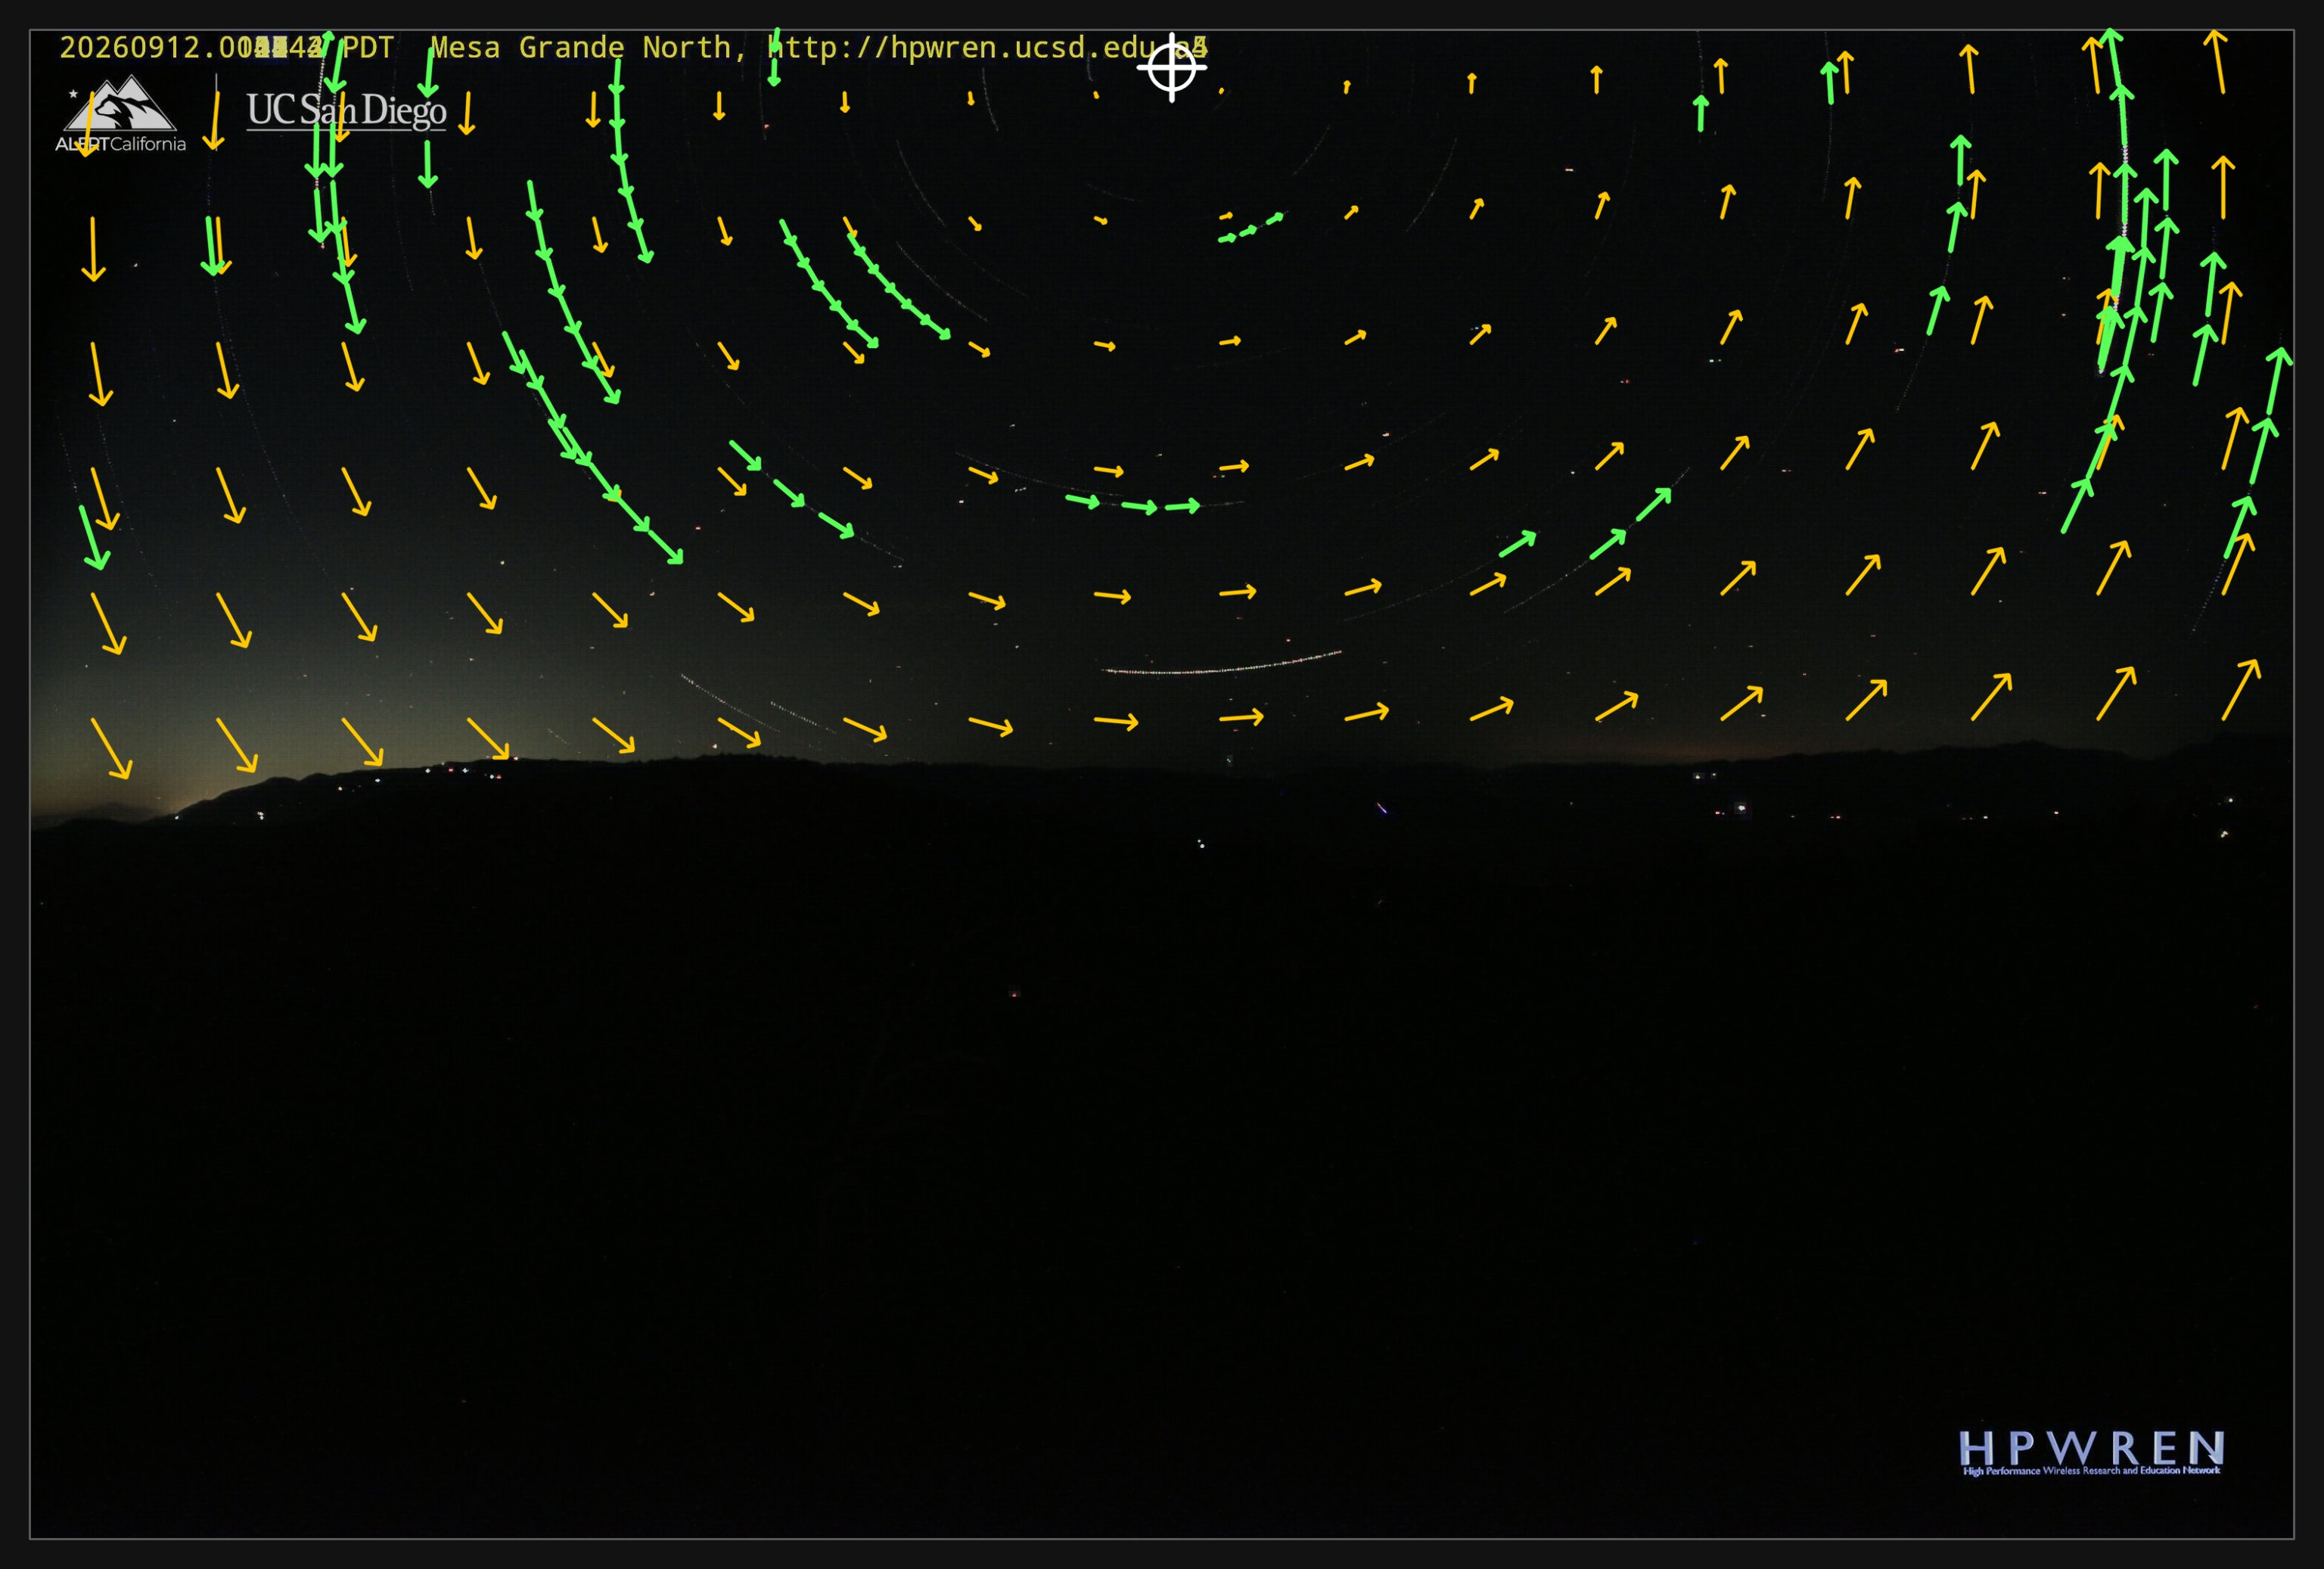

In [3]:
F.velocity_figure(MGN, DAY, crop=False, pad=(40, 40, 40, 40), dim=0.8)

*Mesa Grande North, 00:00–01:30 on 12 September 2026, all 90 frames stacked. Green: the motion of the stars along the trails the solver tracked, each arrow showing how far a star moves in 15 minutes. Gold: the same motion as predicted across the sky from the pole the solver found from those trails (white cross), just inside the top of the frame. Near the pole the sky barely moves; 60° from it, a star travels about 13° an hour.*

Behind the picture is one equation. Through the lens alone, with no orientation needed, each point on a trail becomes a direction **d** in the camera's own frame. The Earth turns about the pole **p** at the sidereal rate ω (once in 23 hours 56 minutes, about 15° an hour), so in the camera's view every star's direction changes at

$$\dot{\mathbf{d}} = -\,\omega\,\mathbf{p}\times\mathbf{d}$$

The minus sign is because the sky turns the opposite way to the Earth. Each pair of neighboring points on a trail gives one measured direction **d** and its rate of change. The equation is linear in **p**, so the pole that fits every trail best comes straight out of least squares, in one step and with no search:

$$\hat{\mathbf{p}} = \arg\min_{\mathbf{p}} \sum_i \left\lVert \dot{\mathbf{d}}_i + \omega\,\mathbf{p}\times\mathbf{d}_i \right\rVert^2$$

Points that don't fit, from aircraft or lit clouds, are dropped, and the fit is repeated. The fit isn't told that **p** has length 1, and it comes out at 1 only when the lens's scale is right. If the lens is assumed to magnify more than it does, every angle comes out too small, and the sky seems to turn too slowly. Therefore, the same fit checks the lens before a single star has been named.

On the east-facing San Miguel camera the pole is out of the picture, up and to the left, but the trails still give it away: each one is a short piece of a huge circle around it, and the fit finds it to within 0.3°.

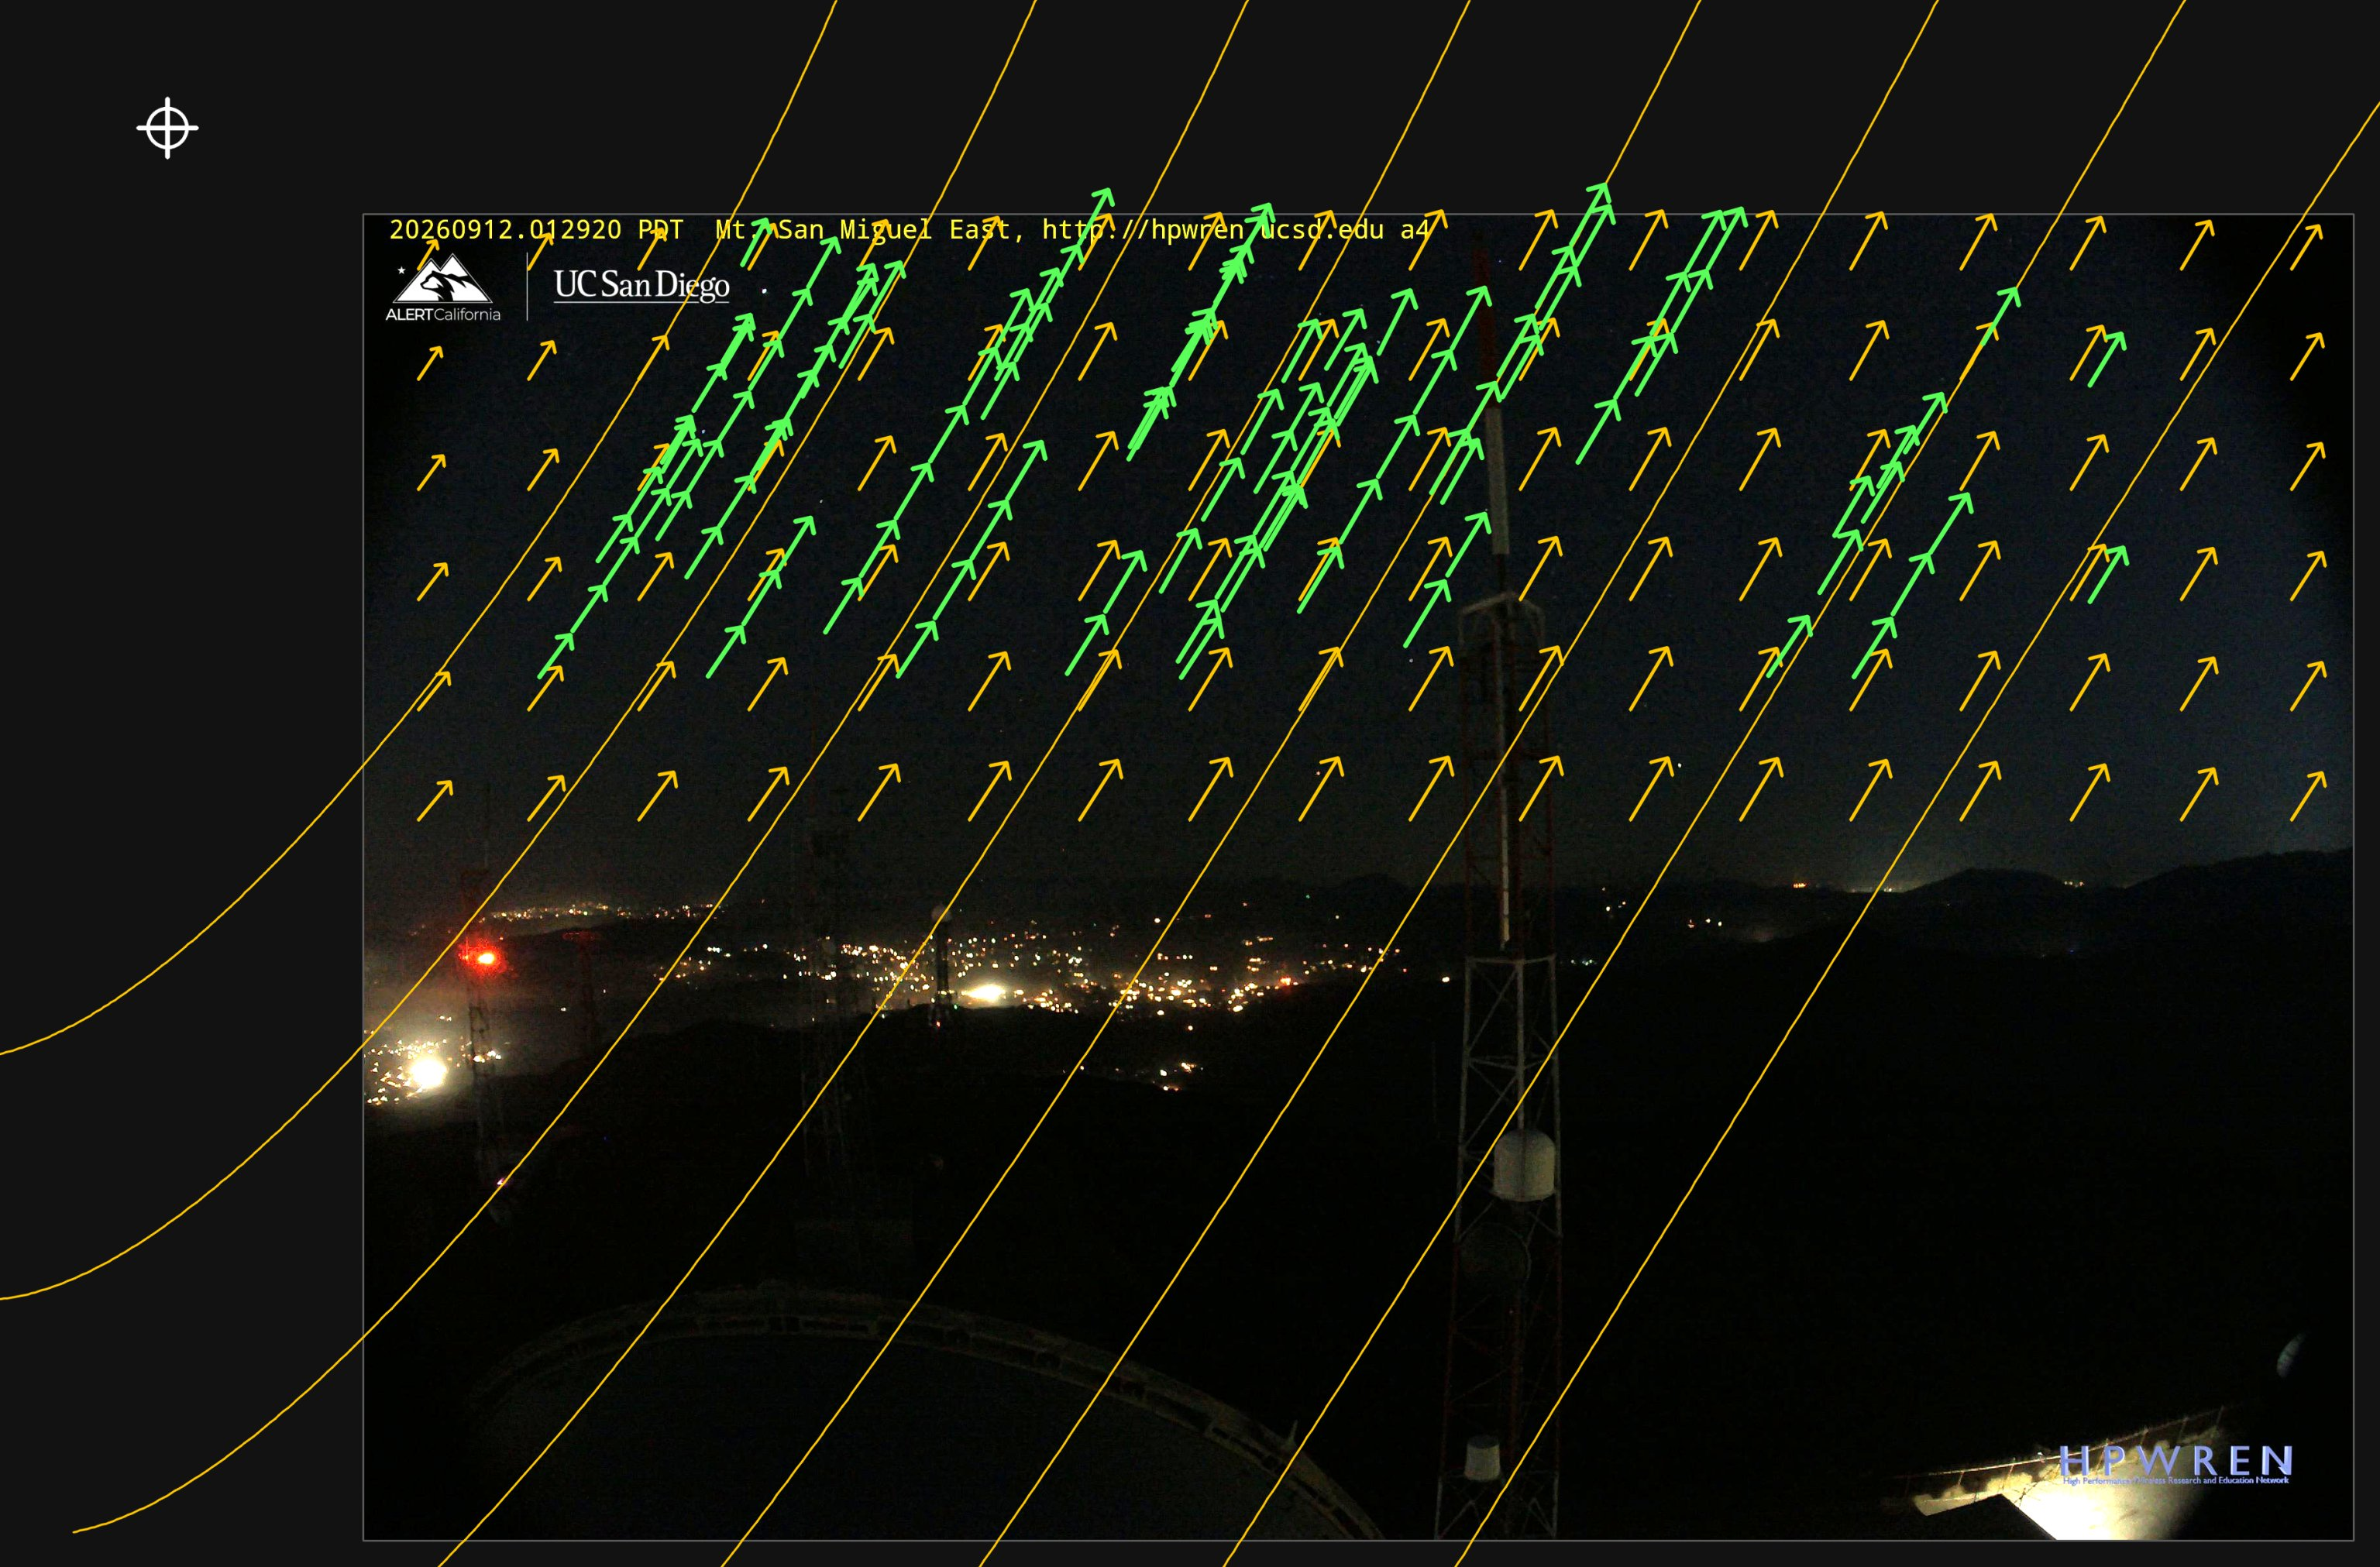

In [4]:
F.pole_figure(SME, DAY, base="last", pad=(560, 330, 40, 40), rhos=range(40, 111, 10), arrows=True)

*San Miguel East, 12 September 2026. The frame sits inside a wider canvas so that the pole (white cross, top left) and the circles about it (gold lines) can be drawn where they fall. Green arrows: the motion of the stars along the trails the solver tracked, each showing how far a star moves in 15 minutes. Gold arrows: the same motion as predicted from the pole.*

### Step 4: Matching the Star Catalog

The pole leaves one angle open: how far the camera is turned about the pole itself. Turning a camera about the pole is the same motion the sky makes through the night, so the trails alone can't tell this camera from the same camera turned a little about the pole and filmed a little later; finding the turn is like setting the clock. That turn changes azimuth, tilt and roll at once. On this east-facing camera it moves mostly the tilt, and on a north-facing camera mostly the roll. So the solver turns the view a full circle about the pole in tenth-of-a-degree steps and scores how well catalog stars land on the trails at each step. One stands out, and then the full fit refines it.

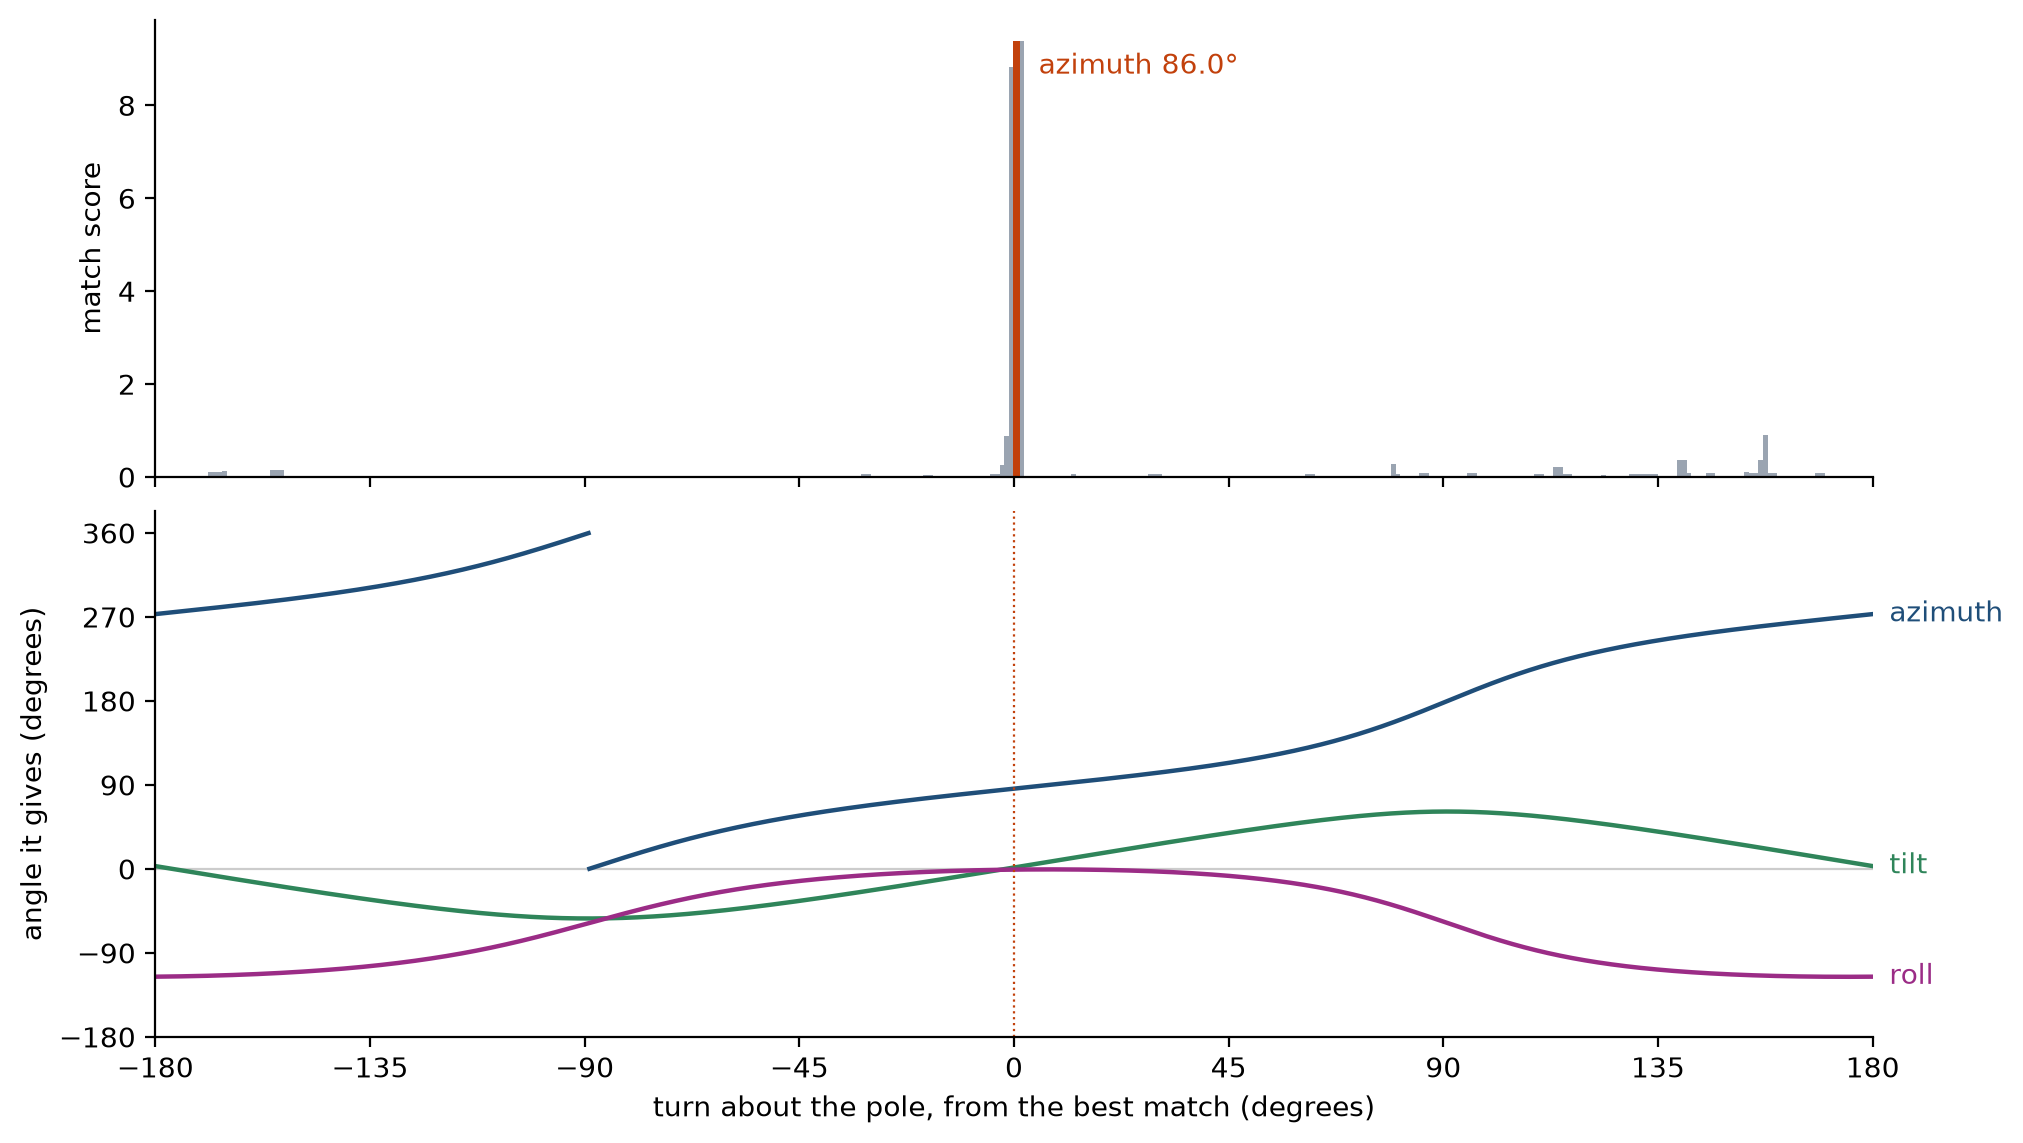

In [5]:
F.heading_scan(SME, DAY)

*Step 4's search on San Miguel East, 12 September 2026. Top: the best score in each 1° of turn about the pole, measured from the best match, which puts the camera at azimuth 86.0°; the full fit then refines that to 86.4°. Bottom: the azimuth, tilt and roll that each turn gives. Near the best match, the turn moves the tilt most.*

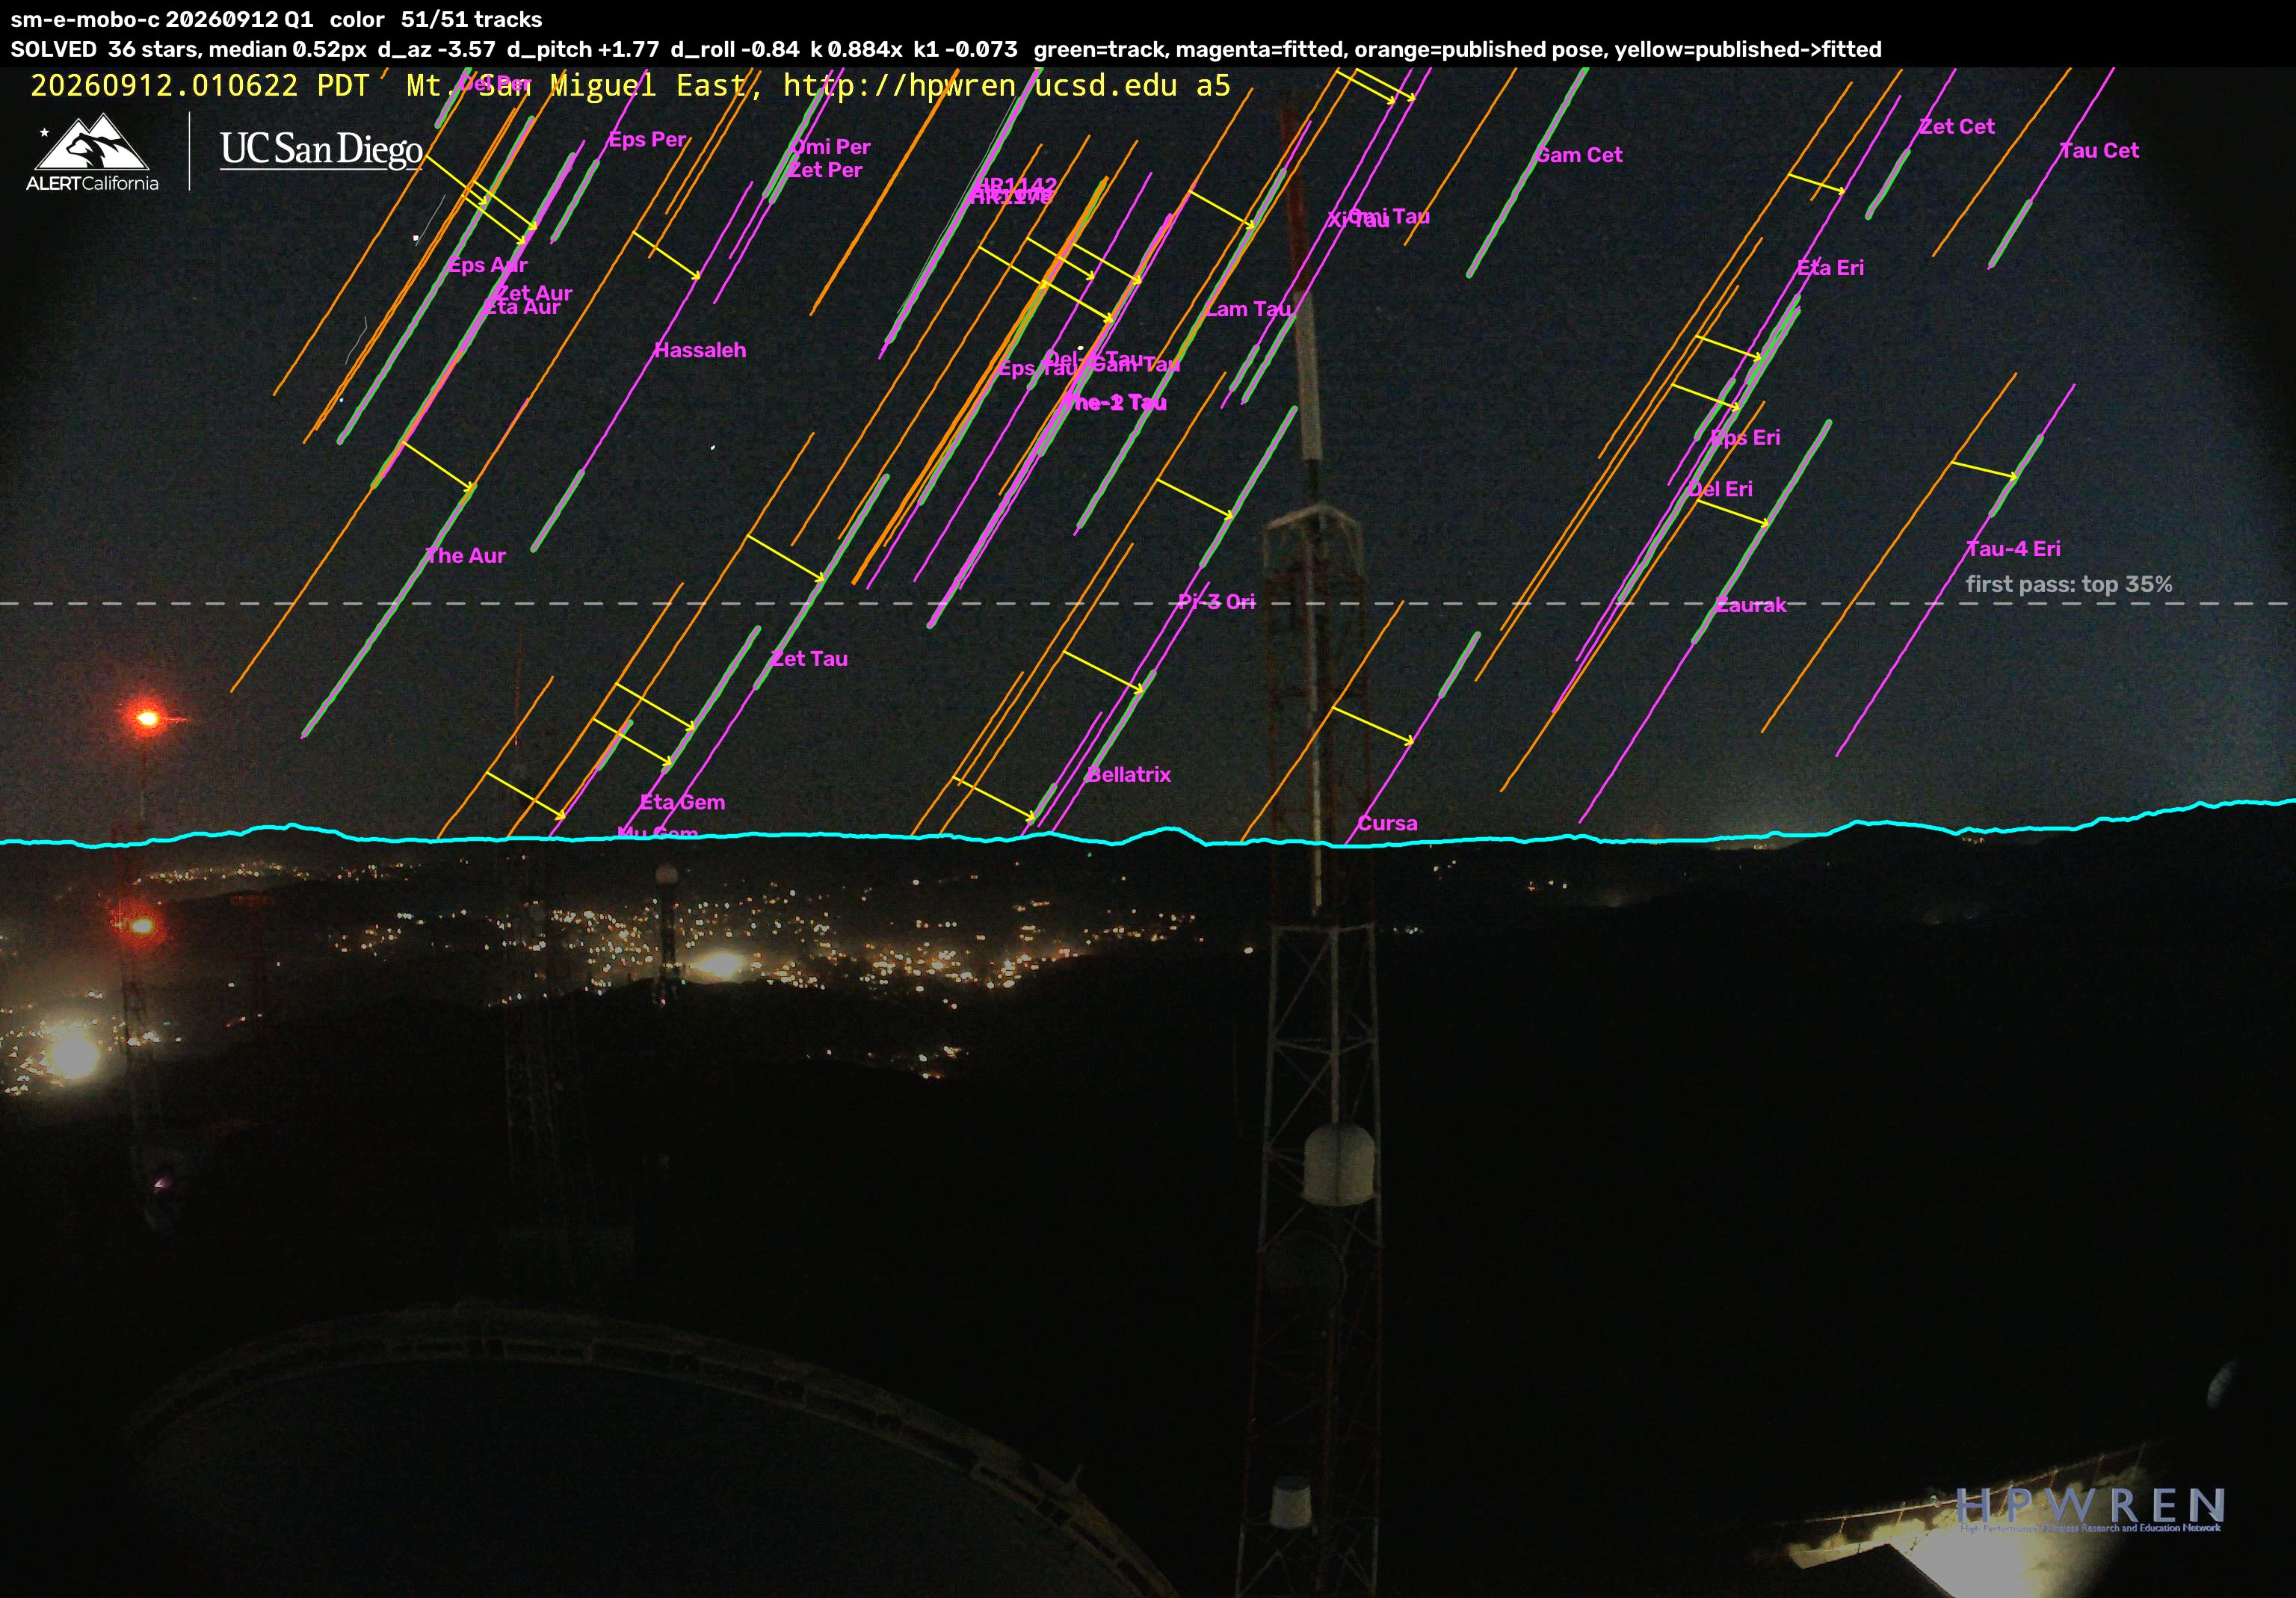

In [6]:
F.solve_overlay(SME, DAY, full=True)

*Step 4 on the color camera. Thick green: star trails over 90 minutes. Thin magenta, running inside them: where the catalog puts each star under the solved orientation. Orange: the same stars under the nominal orientation (due east, level), with yellow arrows from one to the other. Cyan: the skyline from the terrain model, placed by the solved orientation. Dashed: the bottom of the first search, the top 35% of the frame; the trails below it come from the second search, over all the sky above the skyline.*

The result: the camera faces azimuth 86.4° (3.6° north of due east), tilted 1.8° up and rolled 0.8°, and its lens is a fisheye, 109° wide at the horizon, that squeezes the edges of the scene more than the middle, with its optical center a little off the middle of the sensor. Its monochrome neighbor on the same mount comes out facing the same way to about 0.01°.

In [7]:
m = F.solve("sm-e-mobo-m", DAY)
c = F.solve(SME, DAY)
hc = (c["cam"]["az"] + c["r"]["pose"]["d_az"]) % 360
hm = (m["cam"]["az"] + m["r"]["pose"]["d_az"]) % 360
print(f"sm-e-mobo-m: {m['r']['n_stars']} stars {m['r']['median_px']:.2f} px, heading {hm:.2f} vs colour {hc:.2f}: "
      f"{hm - hc:+.2f} deg; centres c ({c['cam_c']['cx']}, {c['cam_c']['cy']}) m ({m['cam_c']['cx']}, {m['cam_c']['cy']})")

frames: 90/90 frames dark enough (sun el <= -8.0)


  2291 raw tracks -> 452 moving, persistent tracks


frames: 90/90 frames dark enough (sun el <= -8.0)


  3090 raw tracks -> 489 moving, persistent tracks


sm-e-mobo-m: 34 stars 0.76 px, heading 86.44 vs colour 86.43: +0.01 deg; centres c (-21.8, -25.2) m (20.6, -17.2)


## Validation

The results of the solver are checked against the stars of a later night, predicted from the calibration alone, the shape of the ground, and HPWREN's own calibration tool.

### Predicting a later night

Unless the camera has been misaligned since it was calibrated, the solver's results should place the stars correctly on a later night. The stars themselves move on: each one rises about four minutes earlier every day, so at the same clock time the whole sky has turned about a degree further west each night, and a whole constellation's width over a month.

For example, the calibration results from September 12th are matched on the same camera at the same time 25 nights later, on October 7th. The stick figures of the constellations are drawn from catalog positions through the solved orientation and lens, then projected onto the frame; nothing has been re-fitted. In September, Orion was only just rising at this hour; by October it stands well clear of the hills, with Gemini beside it. The September calibration still puts every figure on its stars.

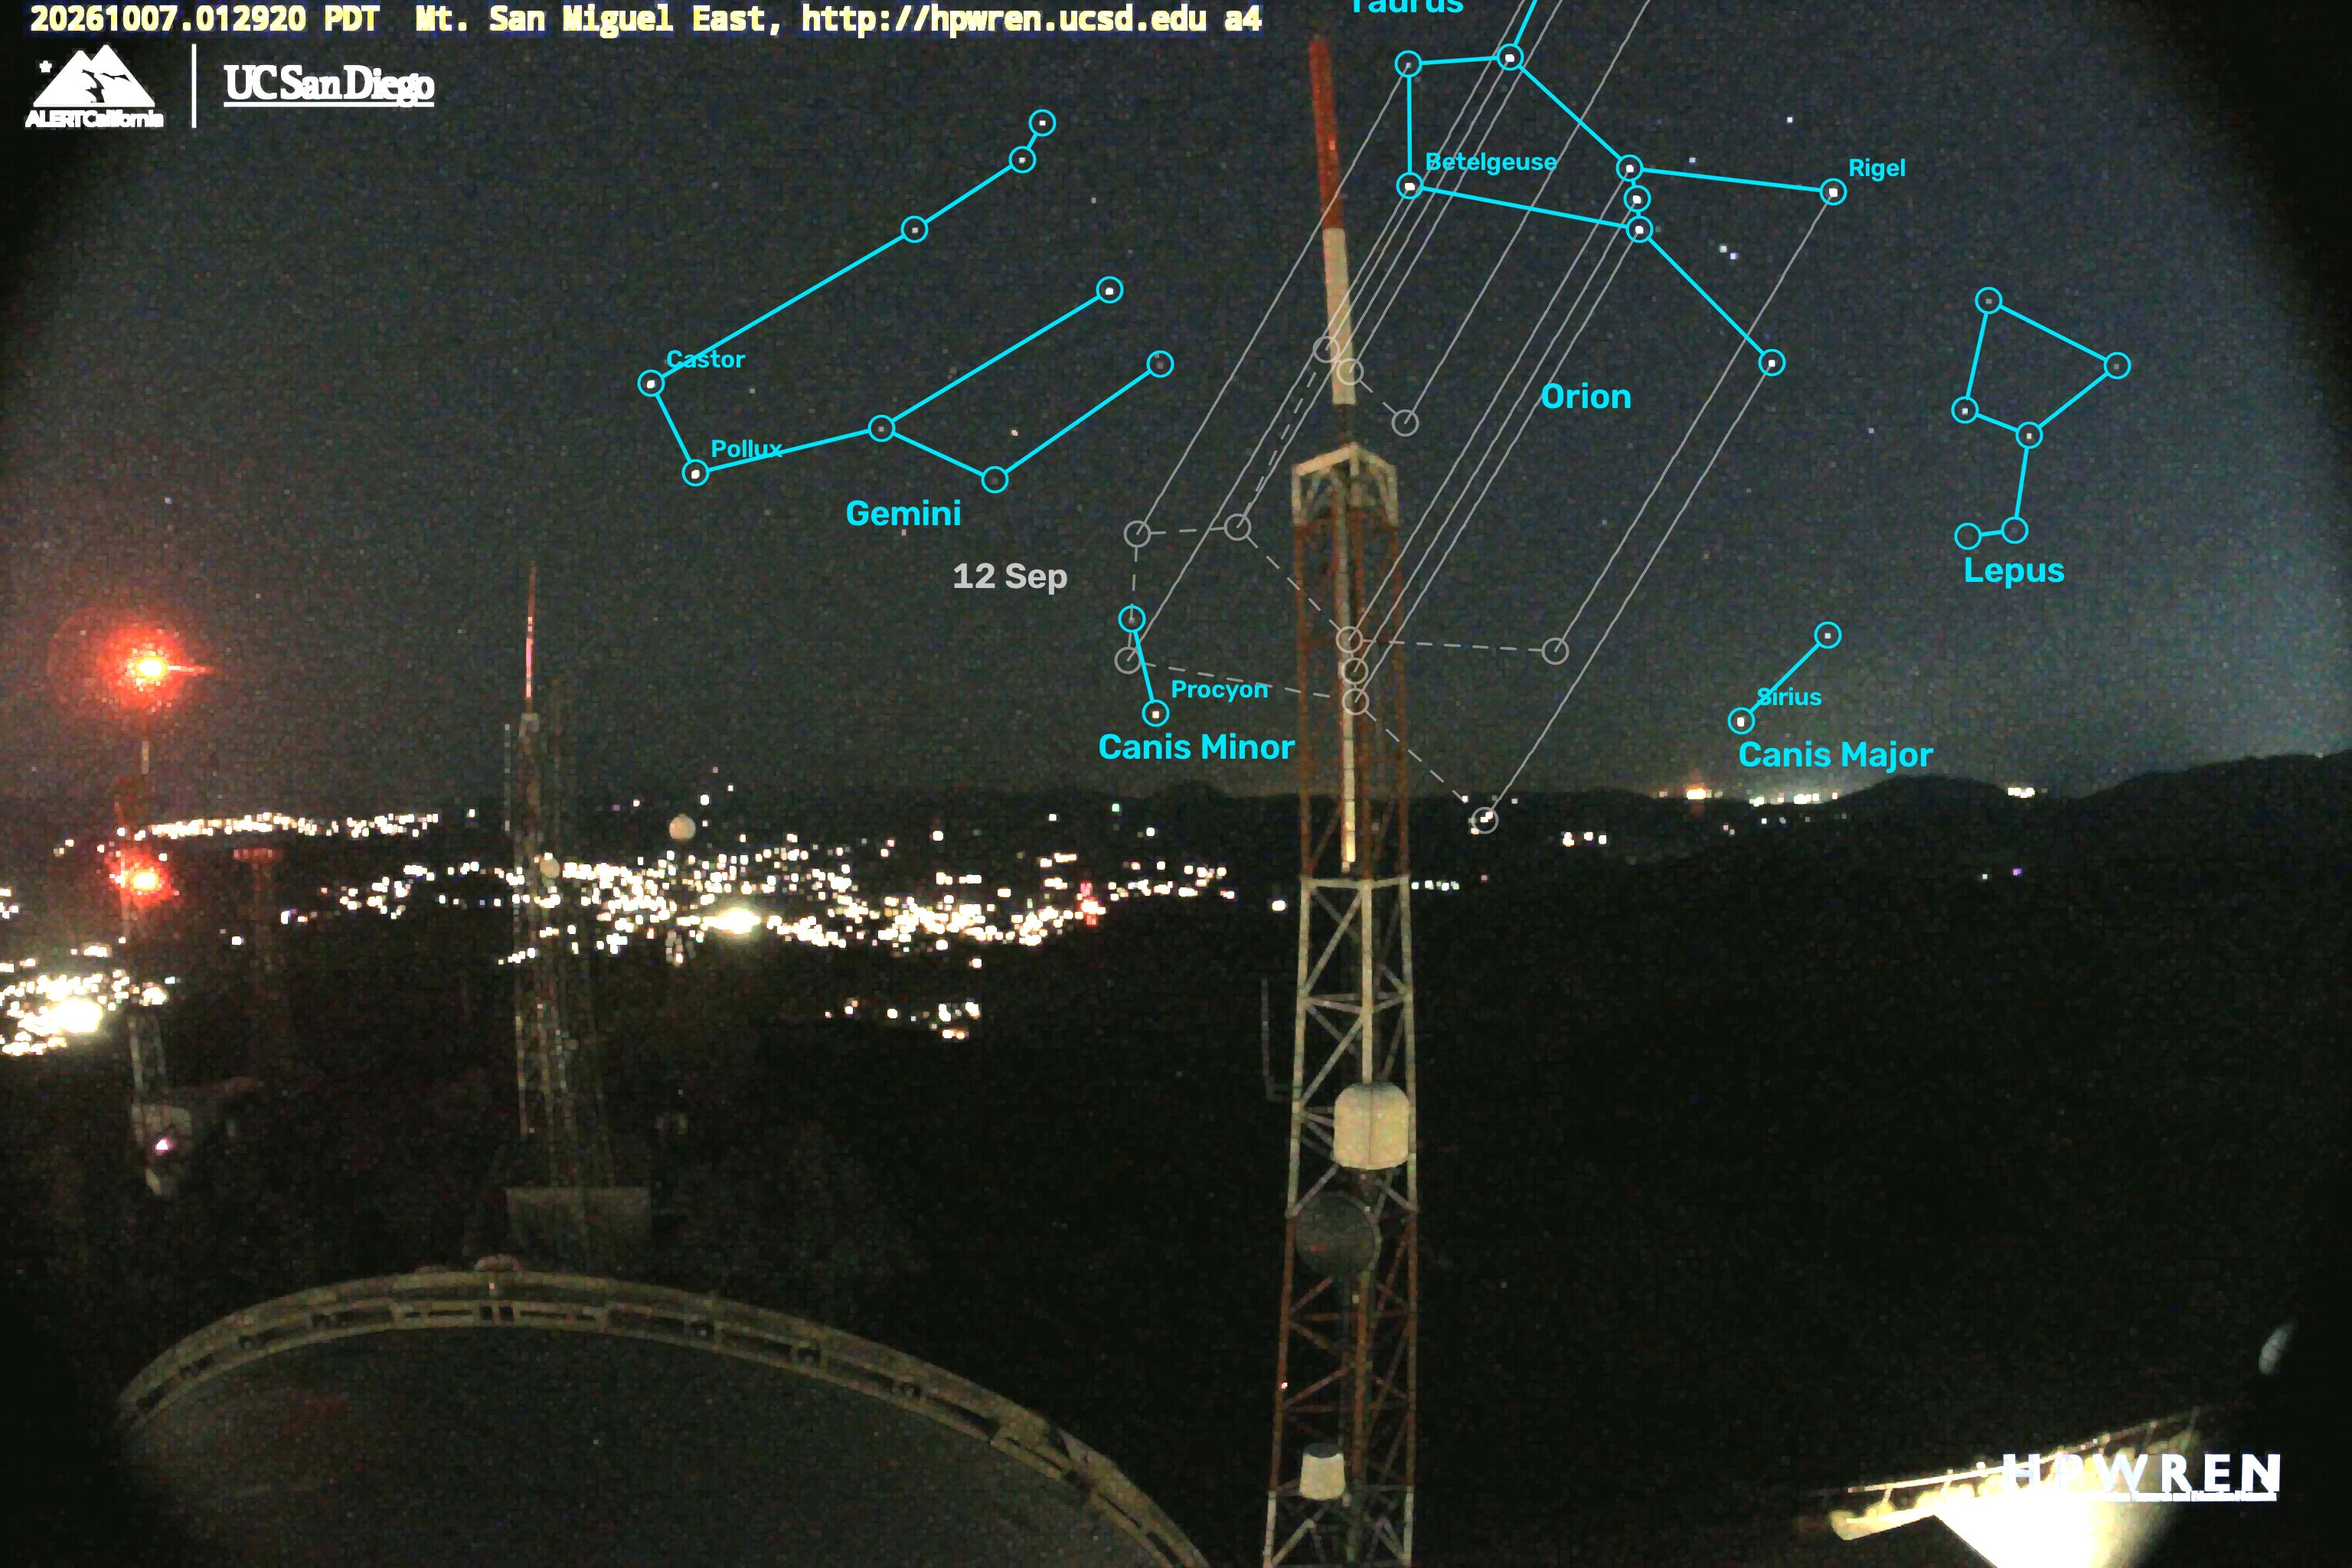

In [8]:
F.constellations(SME, DAY, day="20261007", drift_con="Orion")

*01:29 on 7 October 2026, with the constellations drawn through the orientation solved 25 nights earlier. Faint: where Orion stood at 01:29 on 12 September, the night the camera was calibrated.*

Measured against the stars detected out of single frames, the predictions are off by a median 0.5 pixels three nights later and 1.0 pixel (about 0.03°) 25 nights later, compared to 0.8 pixels on the calibration night itself.

In [9]:
for day in (DAY, "20260915", "20261007"):
    n, hits, med, (dx, dy) = F.star_offsets(SME, DAY, day)
    print(f"{day}: {hits} of {n} stars found, median {med:.2f} px, shift dx {dx:+.1f} dy {dy:+.1f} px")

20260912: 13 of 28 stars found, median 0.79 px, shift dx +0.1 dy +0.2 px


20260915: 16 of 33 stars found, median 0.53 px, shift dx +0.1 dy -0.2 px


20261007: 15 of 32 stars found, median 0.95 px, shift dx -0.5 dy +0.7 px


### Checking against the terrain

A terrain model of the region (the Copernicus 30-meter global elevation model) says, for every direction out from the camera, which ridge should form the skyline and which nearer crests should stand out in front of it. Drawn through the solved orientation onto a daytime frame, those crests should sit on the ridges the camera actually sees.

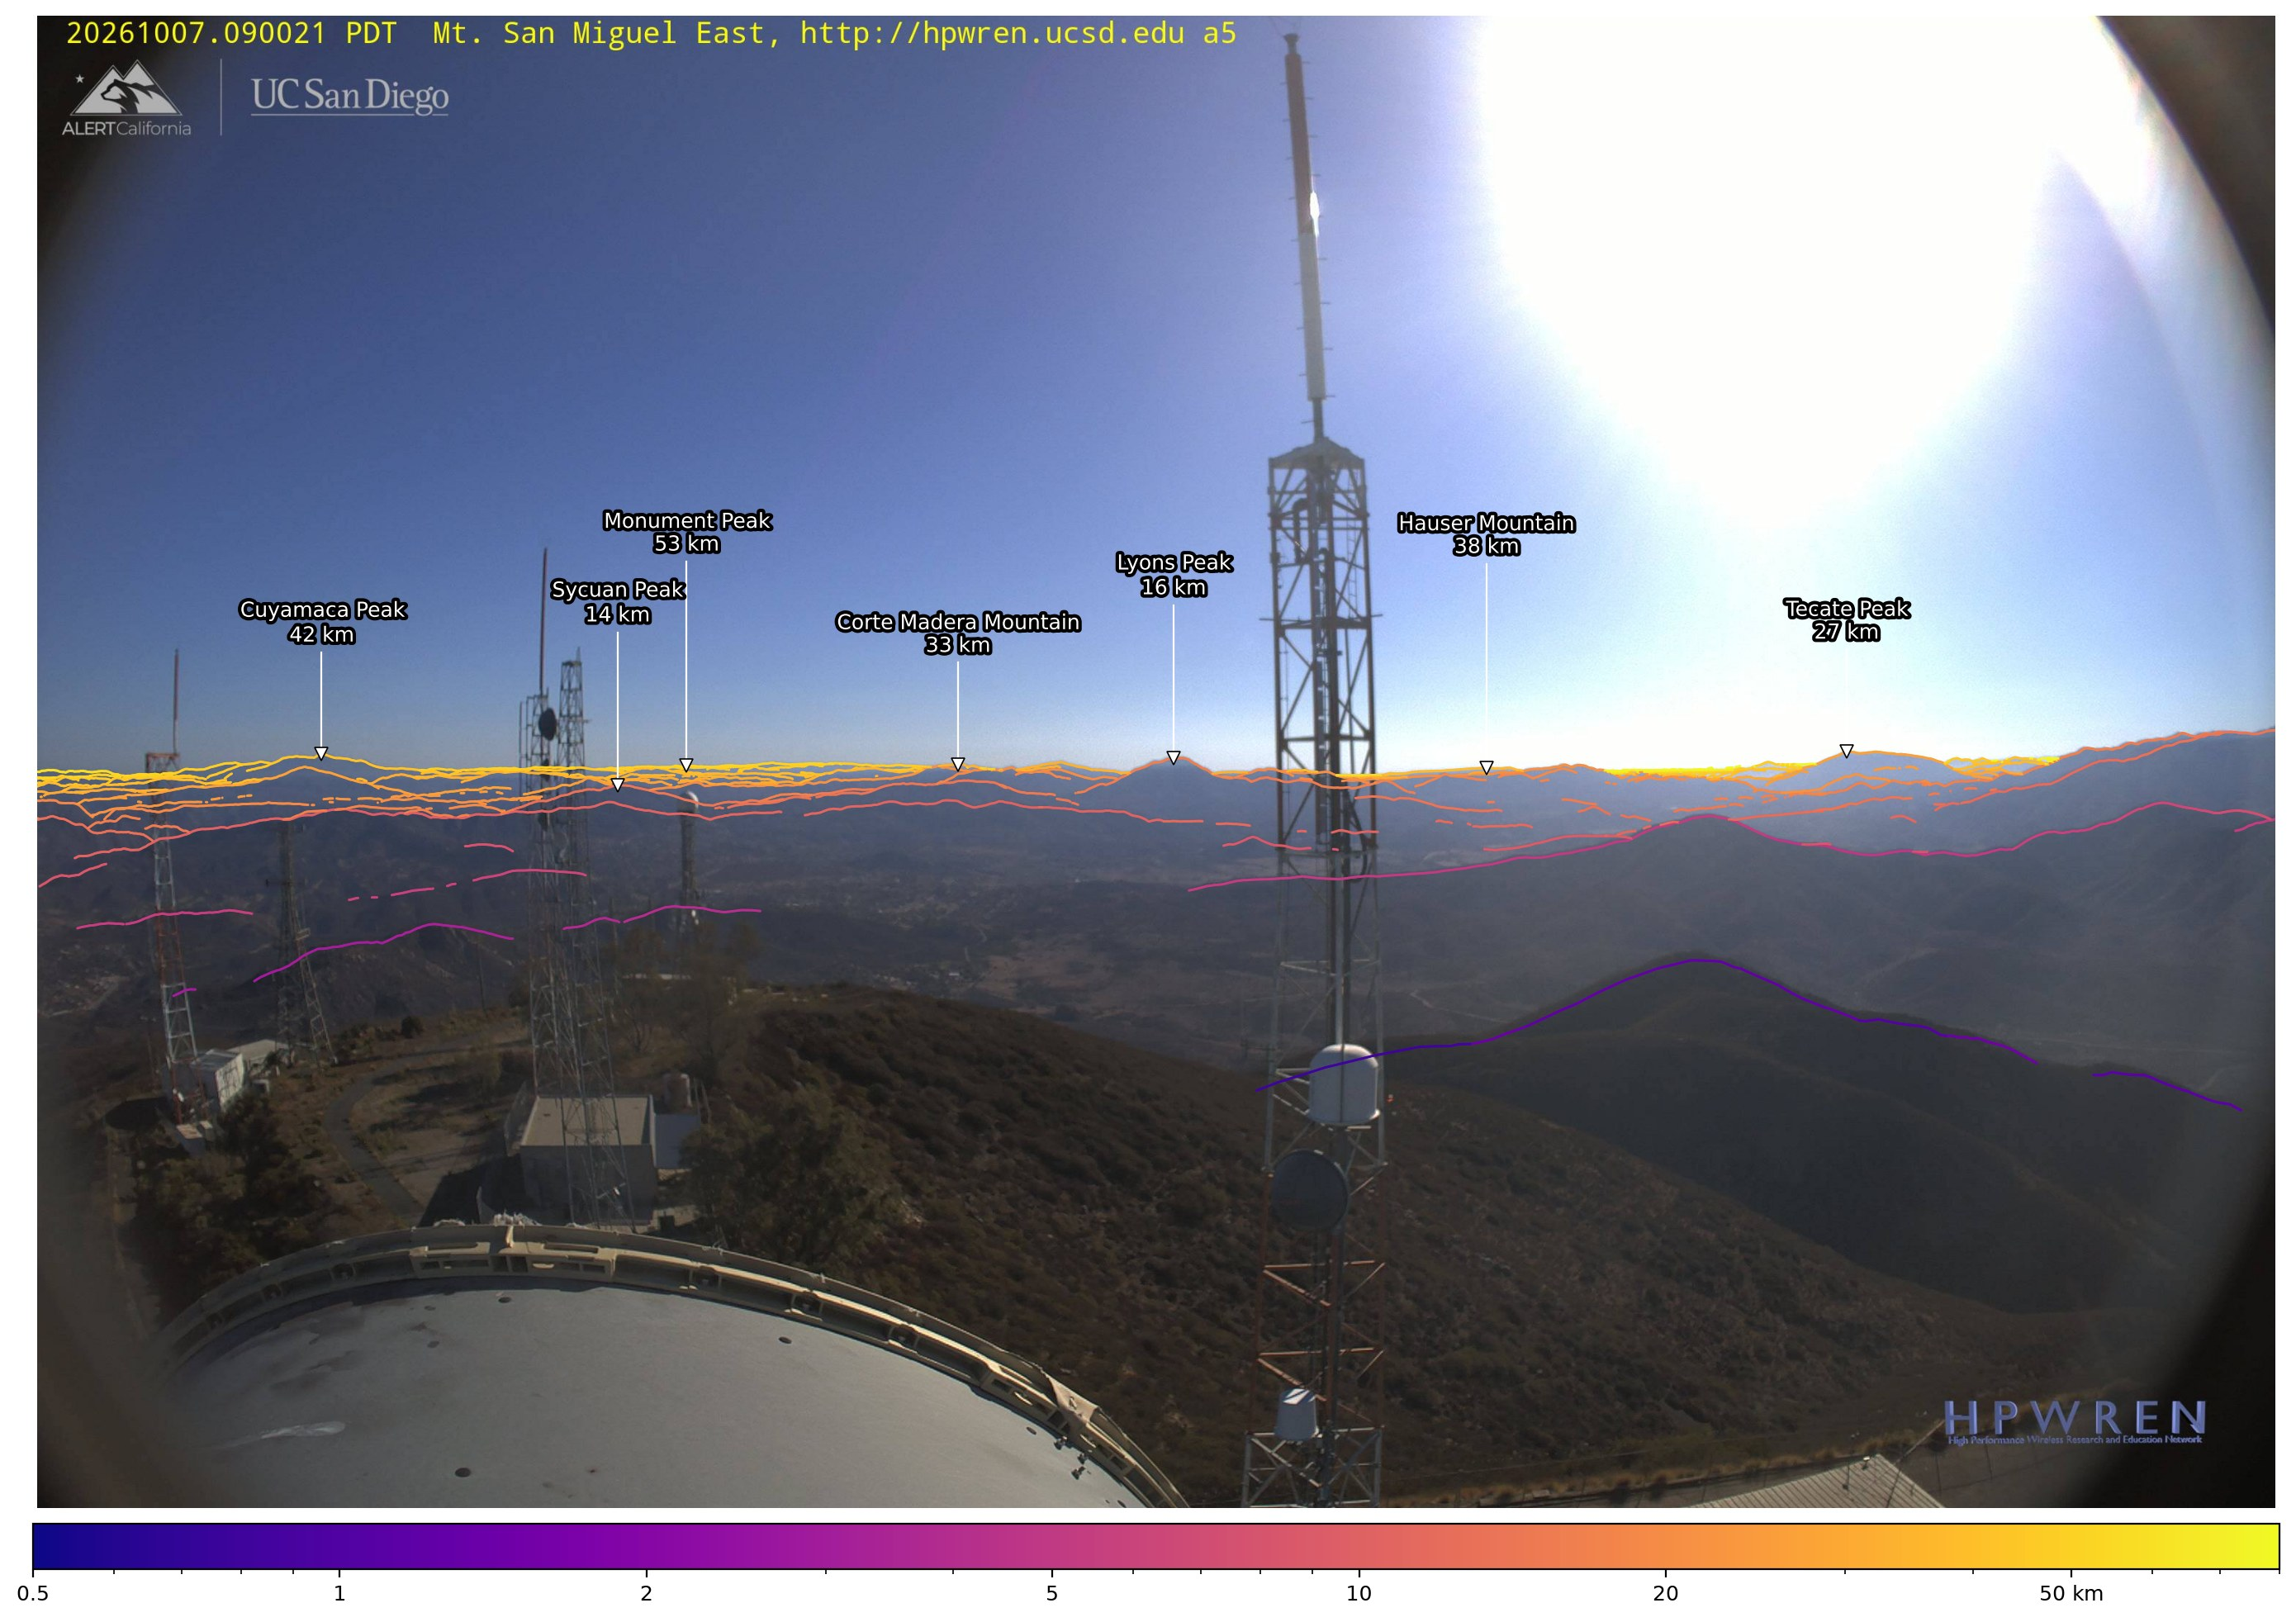

In [10]:
F.ridges(SME, DAY, "20261007", q=4, peaks=F.LABEL_PEAKS)

*09:00 on 7 October 2026, 25 days after the night solved, with the morning sun ahead of the camera. Every crest the terrain model finds, drawn through the 12 September star-solved orientation and lens and colored by distance from the camera: purple for the nearest ridge, half a kilometer away, through to yellow for the skyline 50 kilometers and more away. White triangles: named peaks, placed by the same orientation, with their distances. Nothing is fitted to the picture.*

On the San Miguel camera the solved crests sit within about 3 pixels (about 0.1°) of the terrain's edges across the whole frame. Across the network the same check, on 81 cameras whose skyline is a distant ridge, puts the predicted skyline within 3 pixels of the ridge in the image on four cameras in five, and a median of 1 pixel off overall. The terrain and the stars share nothing, so their agreement is strong evidence that both the orientation and the lens are right, including below the skyline, where no stars are.

In [12]:
print("best vertical shift of the crests (px, negative is up):", F.crest_shift(SME, DAY))

best vertical shift of the crests (px, negative is up): {'nominal': -5, 'solved': -3}


In [ ]:
# The network skyline sentence: static/skyline_v040.json, from scripts/skyline_v040.py
import json
print(json.dumps(json.load(open("static/skyline_v040.json"))["aggregate"], indent=1))

{
 "n_cameras": 81,
 "median_of_medians_px": -1.0006534695667142,
 "mean_abs_of_medians_px": 2.538589444185527,
 "frac_within_3px": 0.7777777777777778,
 "median_mean_abs_px": 4.792375969559085
}


### Checking against HPWREN's tool

The HPWREN team validated these results with an independent calibration tool of their own. It finds stars a different way (single points in each frame, not linked trails) and uses a different star catalog and different corrections for the atmosphere and the slow drift of the sky, so agreement between the two is a real check. HPWREN's tool has calibrated over 300 cameras, and on the cameras both calibrated, their azimuths agree to a median of 0.1°.

## Applications

**Panoramas.** A panorama joins neighboring cameras into one continuous view. Done by eye or by matching features between pictures, the seams can only be as good as what the pictures share, and that is little at night, in haze or across open sky. With each camera's measured orientation, lens shape and lens center, every image can instead be mapped onto a common grid of bearing and elevation before they're joined, so that features crossing from one camera into the next line up closely, and every point in the panorama keeps its true bearing and elevation. The picture below shows it on Buffalo Bump, west of De Luz.

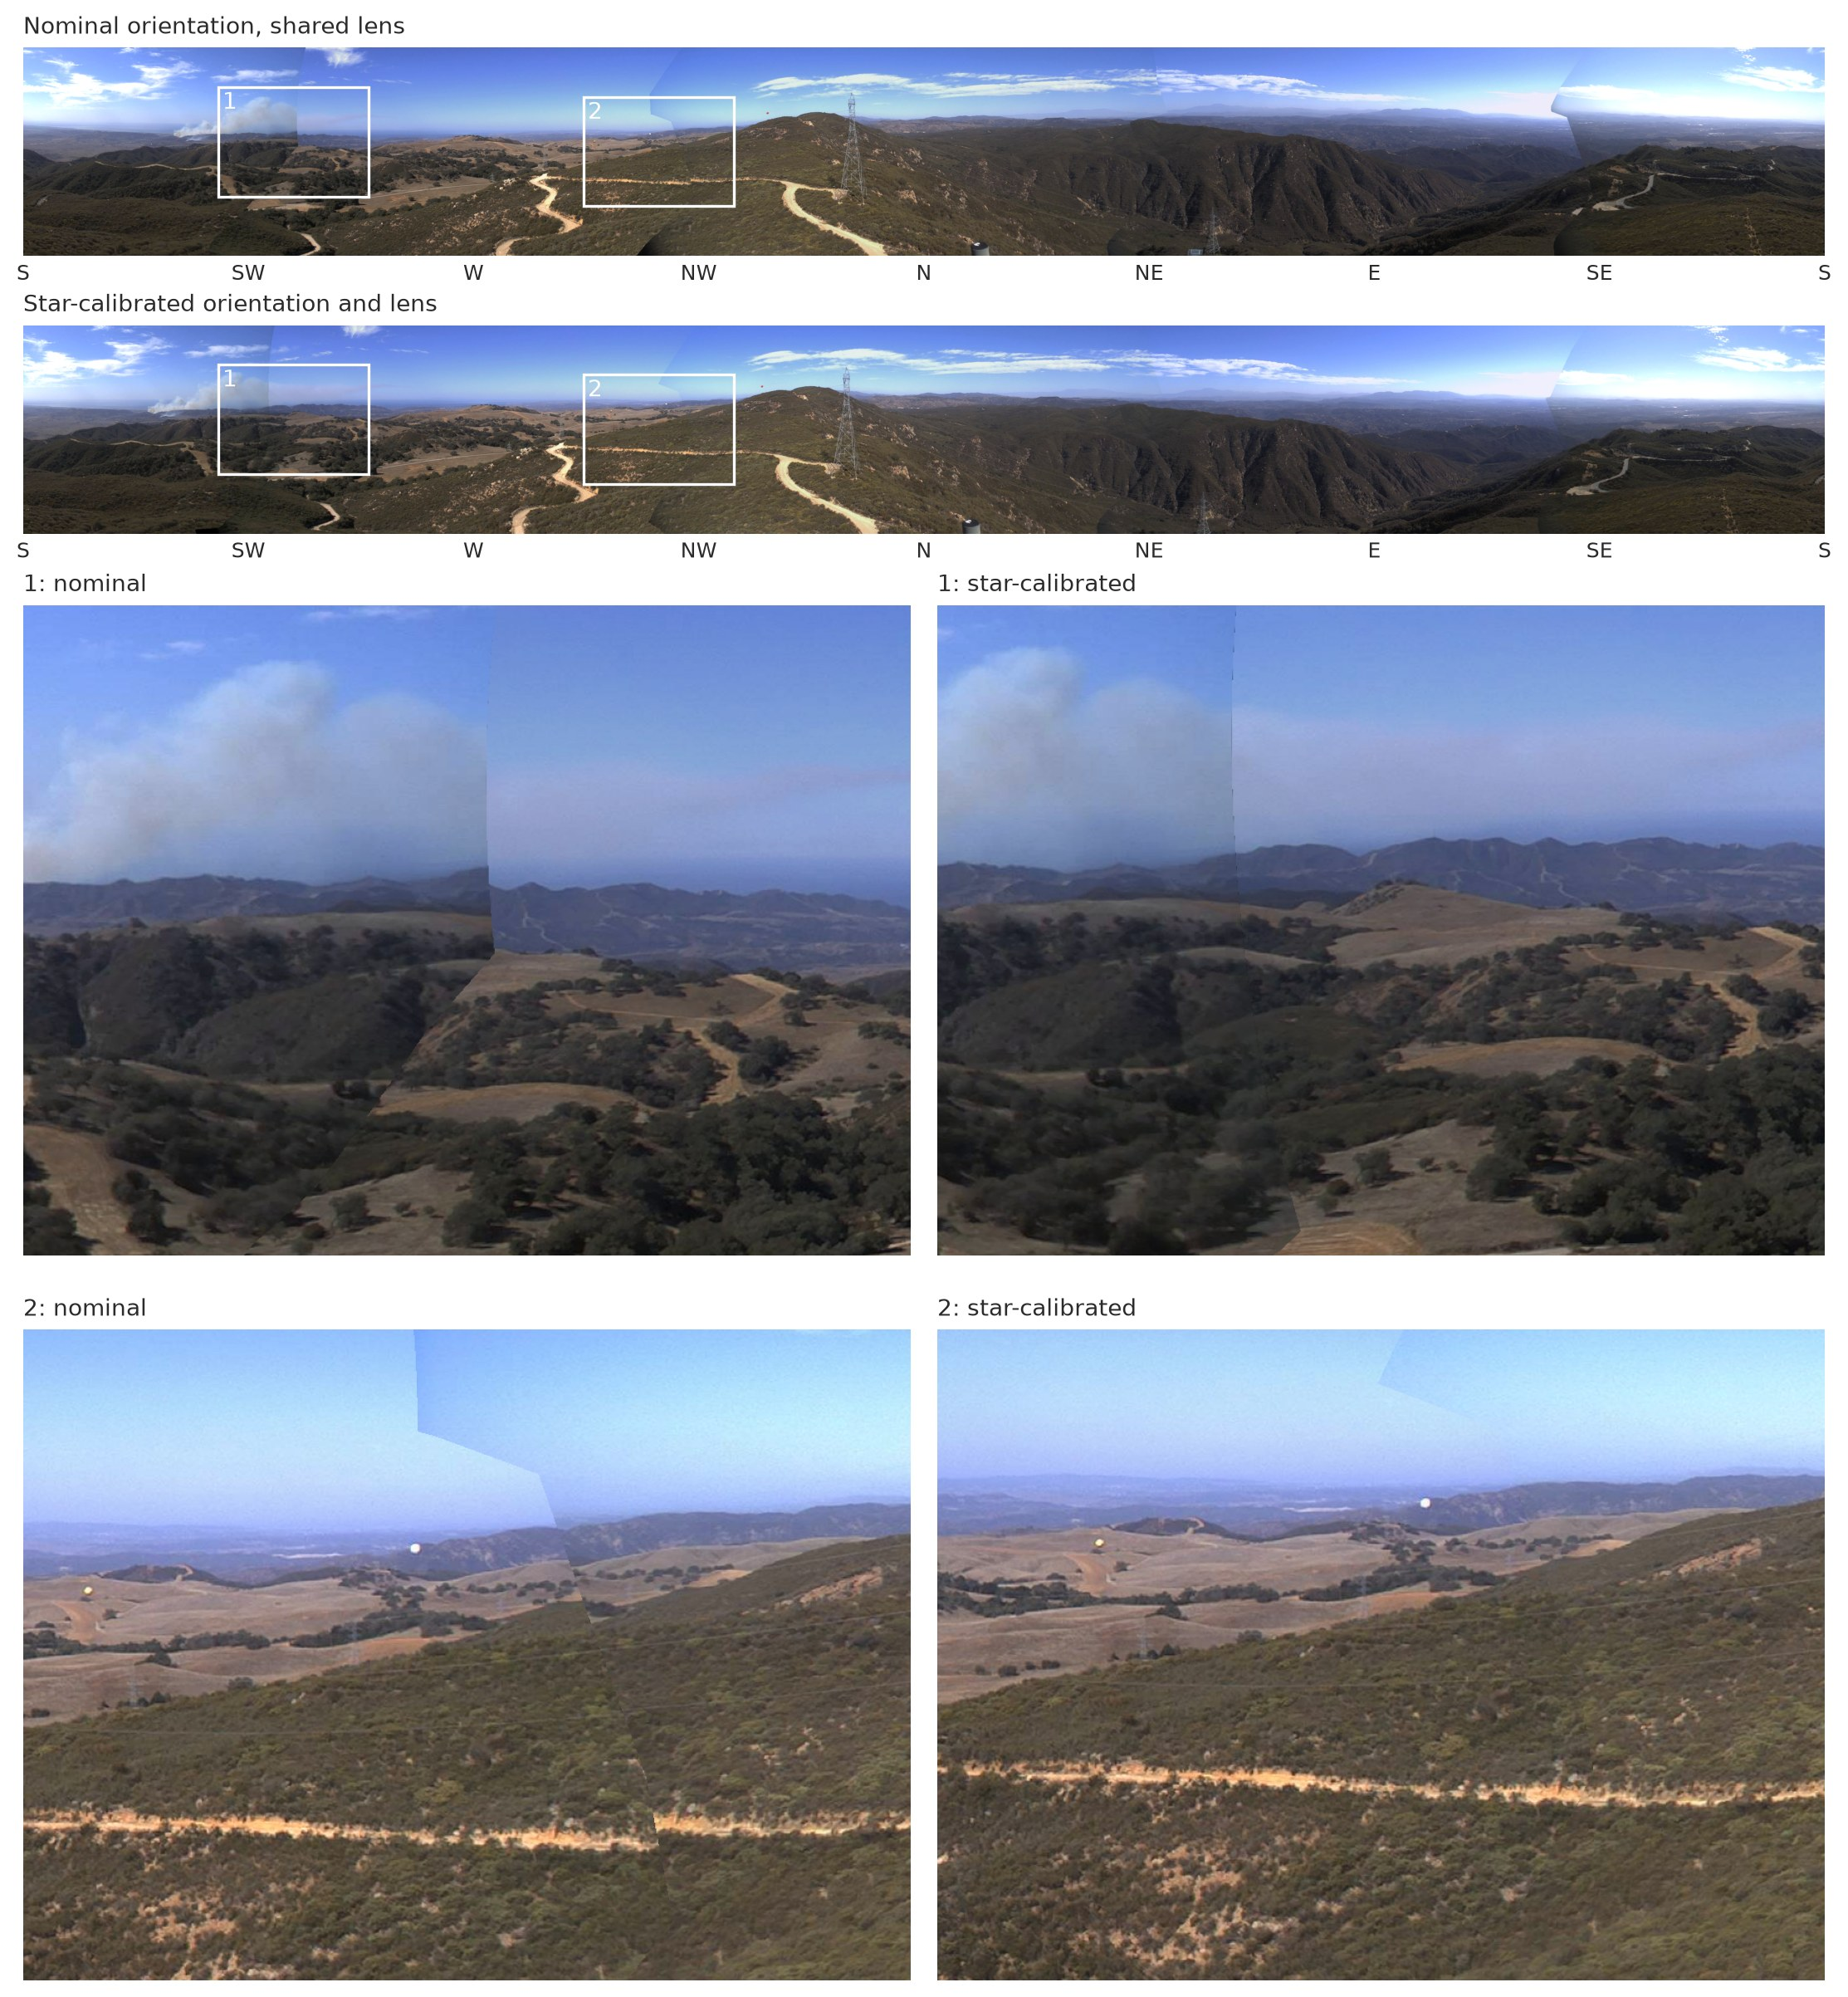

In [2]:
F.panorama("buff", "20261016")

*Buffalo Bump's four color cameras at 10:59 on 16 October 2026, joined onto one grid of bearing and elevation, north in the middle. Each point is taken from the one camera that sees it nearest the middle of its frame, with no blending, so wherever two cameras disagree the picture breaks at the seam between them. Top: through the nominal orientation (due north, east, south and west, level) and a lens shared by all the cameras. Bottom: through each camera's own orientation and lens, solved from the stars on clear nights in September and October; nothing was fitted to the daytime pictures. Below: the two boxed seams up close, to the southwest (1), with smoke from a fire on the horizon, and to the northwest (2), where a dirt road runs from one camera into the next. The sky's shade still changes at the seams, because each camera sets its own exposure.*

**Where is the fire?** A calibrated camera turns a smoke column into a compass bearing, and two cameras' bearings cross at the fire. A single camera's bearing gives no distance, but the terrain can supply part of it.

From a mountaintop, much of the country is hidden behind nearer ridges, so smoke from a hidden valley first shows above the crest in front of it. With the camera's orientation known, the terrain model says how low in the frame smoke from each distance along the bearing could first appear, and where the bottom of the smoke sits rules distances in or out.

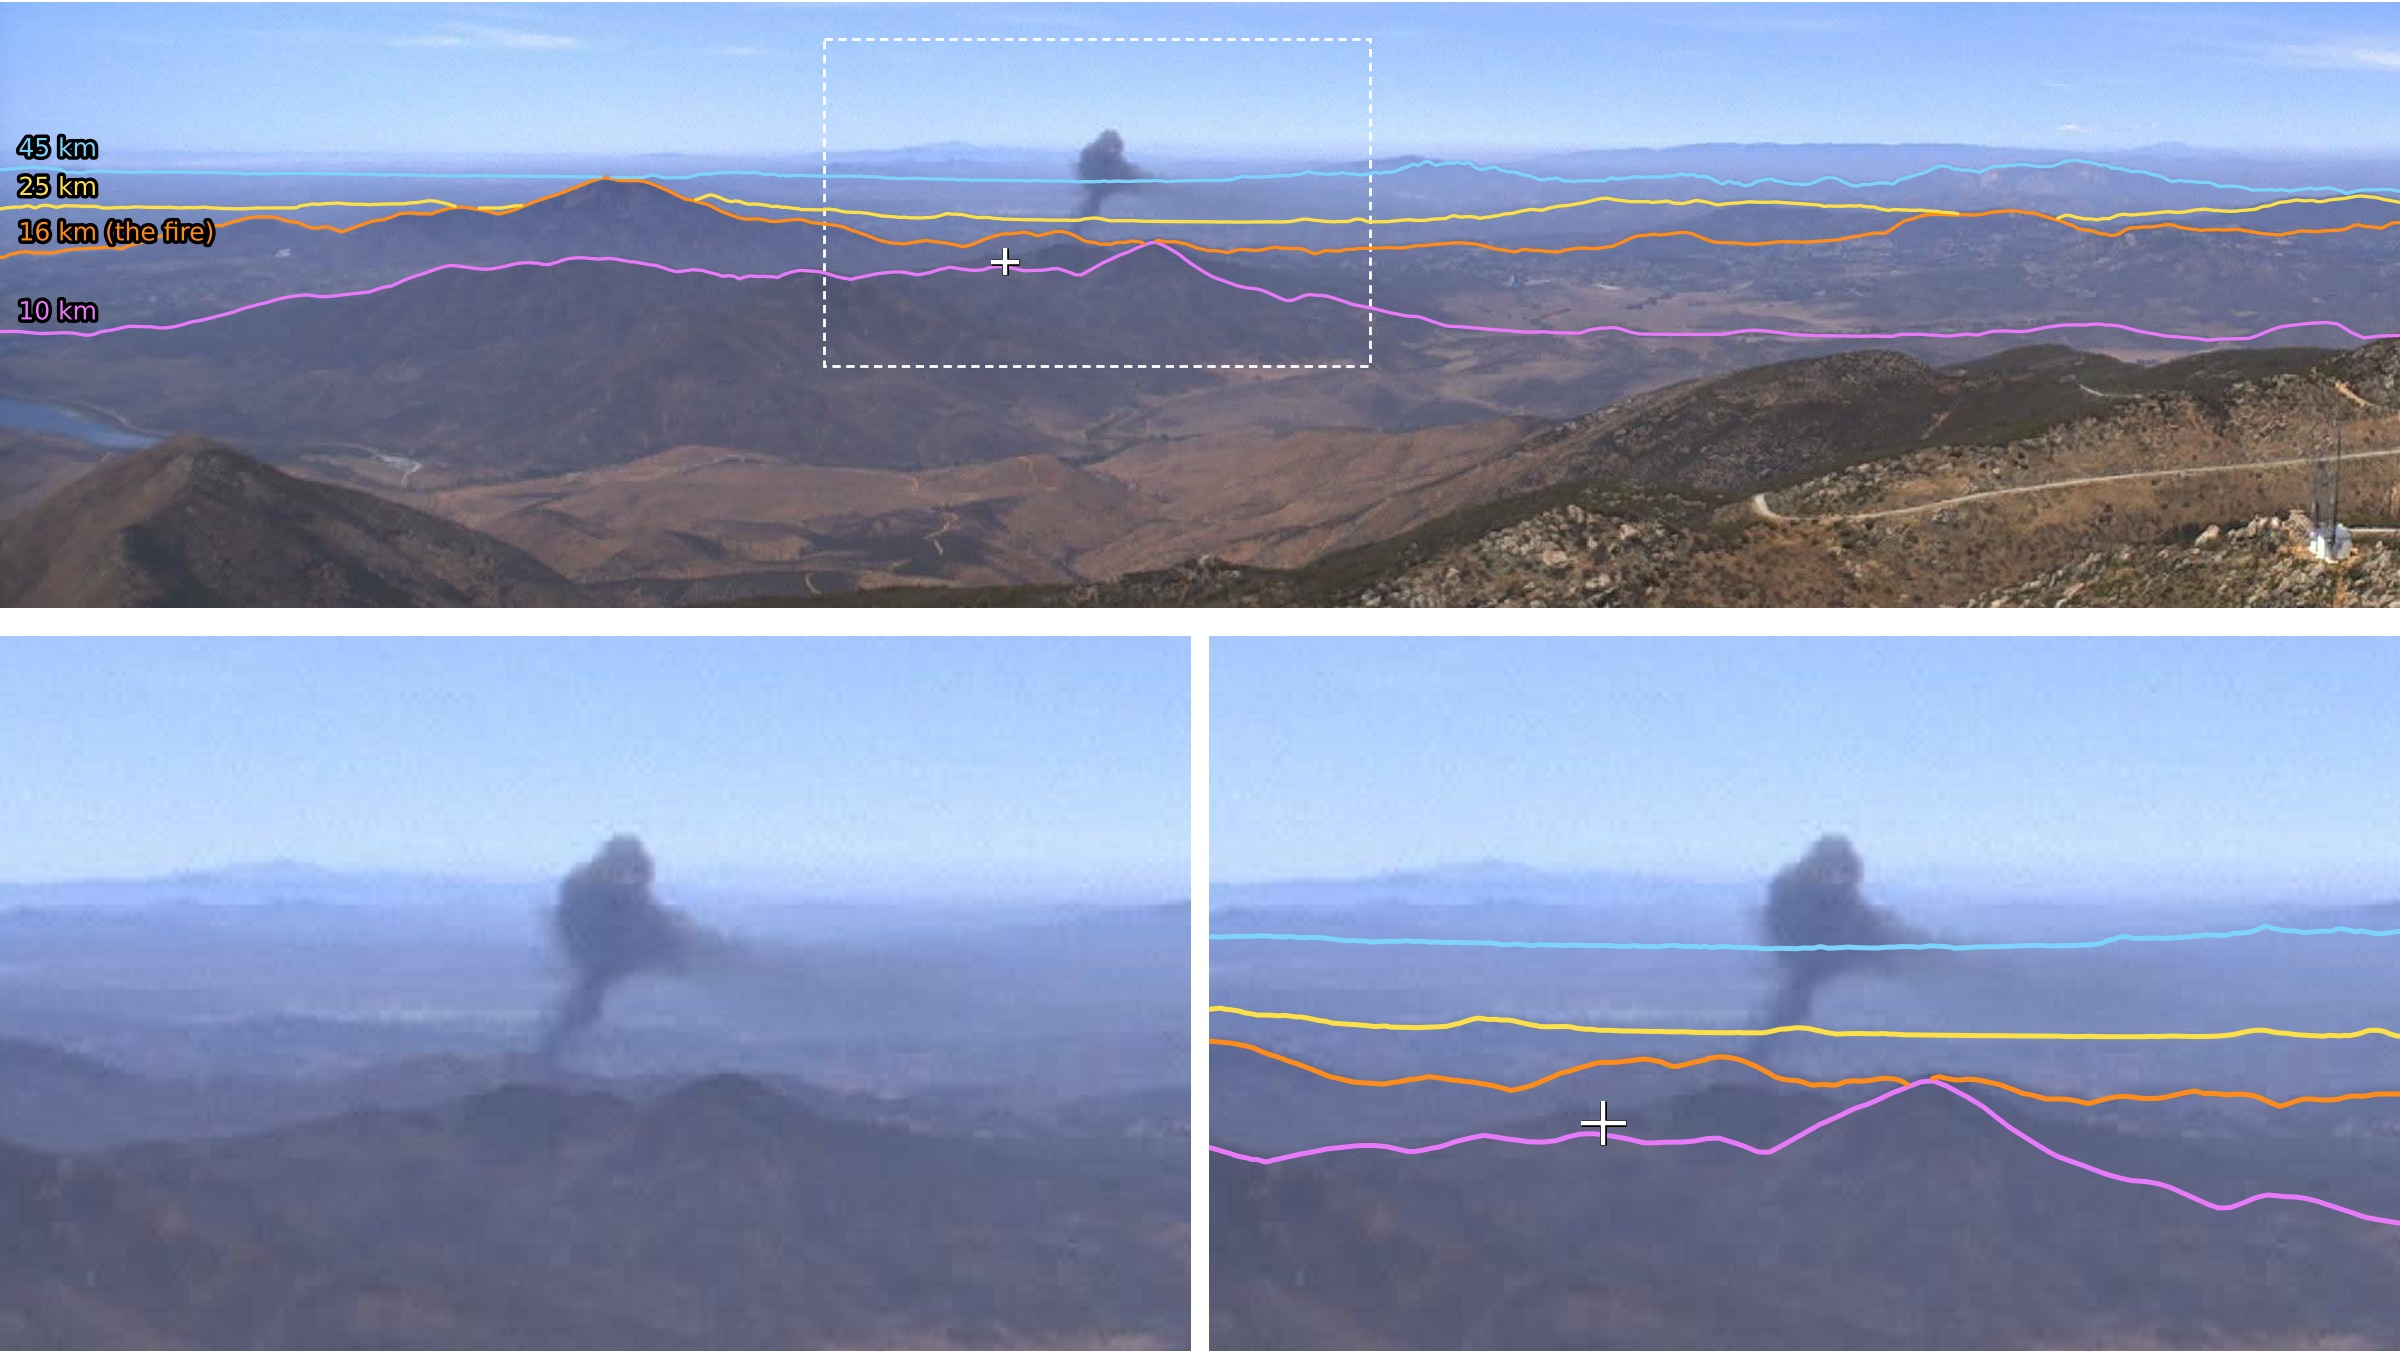

In [ ]:
F.static("between_ridges.jpg")

*The Steele fire from Otay Mountain North, five minutes after ignition on 9 July 2025. Each line is the top edge of the terrain within a given distance of the camera, drawn through the star-solved orientation with nothing fitted to the picture: 10 km (pink), the fire's own 16 km (orange), 25 km (yellow) and 45 km (blue). Top: a wide strip of the frame. Bottom: the boxed area. The foot of the column sits on the orange line, and the column stands in front of the yellow and blue lines, so the fire is nearer than they are. White cross: the official ignition point, 16.3 km away and 0.7° below the crest that hides it.*

On archived fires, the stretch of distance this leaves along each bearing contains the official ignition point on 61 of the 74 bearings that pass within 5° of it.

The terrain helps most where bearings alone are weakest. On the Rainbow fire, two cameras faced each other almost head-on, so their bearings barely crossed. Adding the terrain shrank the likely area from 26 to 5 square kilometers.

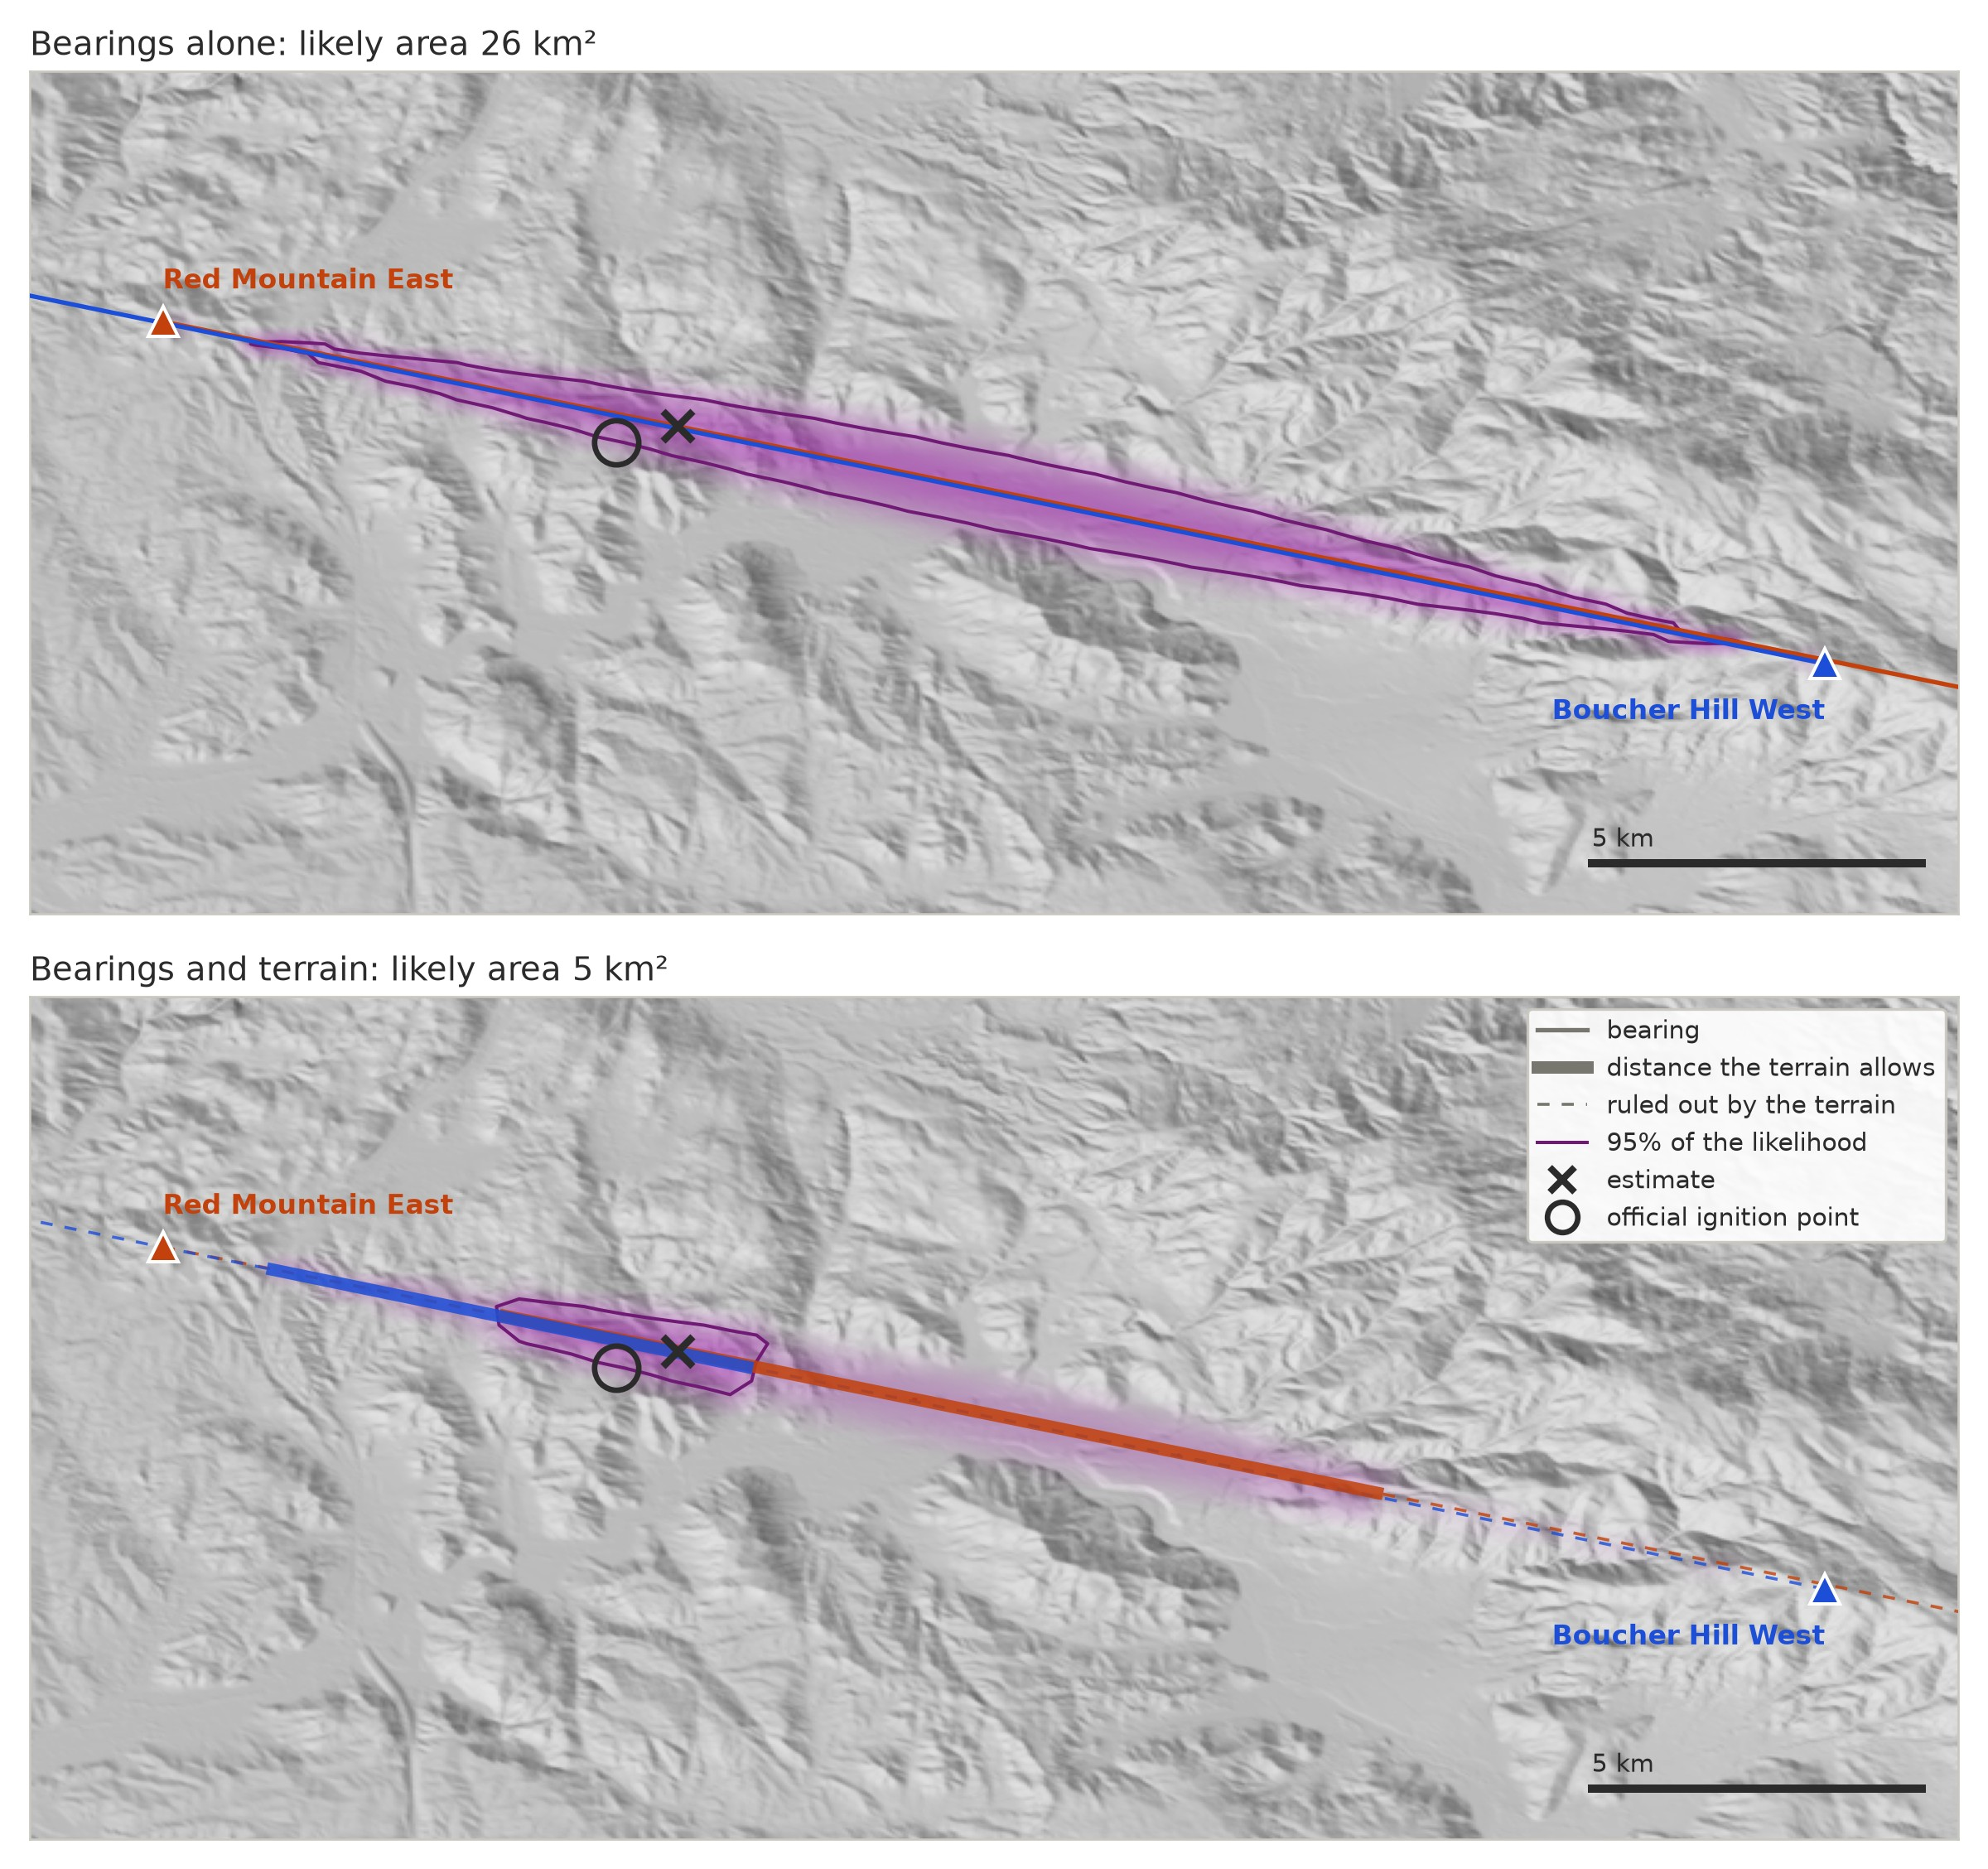

In [ ]:
F.static("terrain_range.jpg")

*The Rainbow fire, 22 July 2026, from Red Mountain East and Boucher Hill West. Top: the two bearings alone, with the likely area (purple, outlined where it holds 95% of the likelihood) stretched along the line between the cameras. Bottom: each bearing limited to the distances the terrain allows (thick): 5.3 to 19.3 km from Red Mountain and 16.9 to 24.6 km from Boucher Hill. The best single estimate (×) stays 1 km from the official ignition point.*

The fire-location work is open source too: [plume-triangulation on GitHub](https://github.com/rharnish/plume-triangulation).


## Across the Network

star-calibration release 0.4.0 was run on 90-minute night blocks from HPWREN's public archive, July to October 2026, on 93 of the network's roughly 370 fixed 90° cameras.

| | |
|---|---|
| Nights tried | 316, on 93 cameras |
| Calibrated | 267 nights, on 89 cameras |
| Stars matched per night | 25 (median) |
| Fit to the star trails | 0.75 pixels (median), about 0.025° |
| Two nights of one camera, under 30 days apart | agree to 0.013° (median); 96% within 0.05° |
| Clear nights, Moon up vs. Moon down | 93% vs. 92% calibrated; orientation equally repeatable |
| Nights that didn't calibrate (49) | 30 too few trails, mostly cloud; 11 no pictures; 8 too few stars to be sure |
| Lens scale | one design across these cameras: within 1% of the same value, except at one site |
| Lens center | a few tens of pixels off the sensor's middle, so measured per camera |
| Lens, from more nights | its error in where pixels point falls from ¼ pixel on one night to 1/10 from three |


In [18]:
import json
print(json.dumps(F.moon_numbers(), indent=1))

{
 "down": {
  "clear": 146,
  "solved": 134,
  "illum_median": 0.016984198514077453,
  "el_median": -54.33520433748039,
  "ratio": 1.0,
  "sep": 0.02052286454293291,
  "n_pairs": 43,
  "n_cal": 127
 },
 "up": {
  "clear": 107,
  "solved": 100,
  "illum_median": 0.747993877793016,
  "el_median": 35.01359488251442,
  "ratio": 1.0571428571428572,
  "sep": 0.02115710762215318,
  "n_pairs": 125,
  "n_cal": 89
 }
}


In [16]:
import json
print(json.dumps(F.nights_numbers(), indent=1))

{
 "star_fit_px": 0.7505648135662307,
 "night_to_night_px": 0.4056395784251092,
 "deg_per_px": 0.03306566178571463,
 "by_n": {
  "1": {
   "pairs": 257,
   "cameras": 86,
   "centre_med": 1.8469720703084909,
   "centre_p90": 4.739741207709341,
   "shape_top_med": 0.27464713192963774,
   "shape_top_p90": 0.7093754522863422,
   "shape_low_med": 0.2881303465763324,
   "shape_low_p90": 0.8225854513001614
  },
  "2": {
   "pairs": 84,
   "cameras": 13,
   "centre_med": 1.2097236944141856,
   "centre_p90": 2.694956677076415,
   "shape_top_med": 0.16351009327802563,
   "shape_top_p90": 0.39818820907636554,
   "shape_low_med": 0.18323315057847117,
   "shape_low_p90": 0.49289640409338525
  },
  "3": {
   "pairs": 32,
   "cameras": 4,
   "centre_med": 0.6193607044827814,
   "centre_p90": 1.226935285963369,
   "shape_top_med": 0.11103429926903392,
   "shape_top_p90": 0.1835740351480448,
   "shape_low_med": 0.13012925687960886,
   "shape_low_p90": 0.2692368915804779
  },
  "4": {
   "pairs": 16,
 

In [19]:
import json
print(json.dumps(F.network_numbers(), indent=1))

{
 "nights": 316,
 "cameras": 93,
 "solved": 267,
 "solved_cameras": 89,
 "stars_median": 25.0,
 "px_median": 0.7505648135662307,
 "deg_median": 0.02481792227363894,
 "agree_median": 0.013412741107104525,
 "agree_p90": 0.035080515015262624,
 "within_005": 0.9635627530364372,
 "n_pairs": 247,
 "failed": 49,
 "dark": 30,
 "no_rotation": 4,
 "too_few": 15,
 "first": "20260703",
 "last": "20261010",
 "k_shared_median": 0.8859801564264809,
 "k_within_1pc": 1.0,
 "k_n_wide": 8
}


**Credits.** Camera images: [HPWREN](https://www.hpwren.ucsd.edu/), University of California San Diego. Archived fire sequences: the FIgLib collection, from HPWREN. Terrain: Copernicus DEM GLO-30, © DLR e.V. 2010–2014 and © Airbus Defence and Space GmbH 2014–2018, provided under COPERNICUS by the European Union and ESA. Star positions: the HYG star database. Peak names and positions: Wikidata. Thanks to Emilia Farcas, Frank Vernon and Hans-Werner Braun for their review and advice.